# Beyond the Cluster: Which Israeli Local Authorities Out- and Under-Perform Their Socio-Economic Standing in National Achievement Tests?

**Introduction to Data Science — Final Project**
Stav Tchizik (316062835) · Or Cohen (206631509)
Ministry of Education Meitzav scores, 2016–2018 × CBS Socio-Economic Index of Local Authorities, 2017 edition

---

## Research question

**Which local authorities in Israel score higher or lower on national tests than their socio-economic level
would predict, and what sets those authorities apart?**

Two smaller questions support it: how closely the socio-economic index tracks test scores in the first place,
which gives us the baseline the deviations are measured against, and whether grouping authorities by their
achievement profiles reproduces the official CBS socio-economic clusters (1–10).


## Setup

Imports and create the random seed, `RANDOM_STATE = 42`. Every step that involves randomness later on (the train /
validation / test split, cross-validation, Random Forests, K-Means) takes its seed from this constant, so the
results can be reproduced exactly.

In [274]:
import random
from pathlib import Path

import numpy as np
import pandas as pd

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

DATA_DIR = Path("datasets")
EDUCATION_PATH = DATA_DIR / "performances_by_areas_years_2015_2019.csv"
CBS_PATH = DATA_DIR / "t01_2017.xls"

## Loading the data

**Ministry of Education Meitzav scores.** A clean CSV with one row per authority × year × sector (`norm_id`) ×
grade (`shichva`) × subject. It loads as is.

**CBS socio-economic index, 2017 edition.** The Excel sheet `t01` was laid out to be printed, not analysed:

- Rows 0–9 are a bilingual (Hebrew / English) header spread over several rows. Rows 8–9 inside that block are
  not authorities but national summary rows (`AVERAGE` and `NATIONWIDE VALUE`).
- The 255 authorities sit in rows 10–264.
- After a blank row, the last 5 rows are footnotes (`*`, `**`, `***`, `(1)`, `..`).

We skip the header block, keep only rows that have a numeric 1–10 cluster (which drops the blank row and the
footnotes). Instead of the multi-row header
we give the columns short English names. Each of the 14 variables the index is built from comes as three
columns: the raw value, a standardized value (`_z`) and the rank among the 255 authorities (`_rank`). The CBS
marks suppressed cells with `..` ("not for publication"), and these become missing values.

Loading the education dataset:

In [275]:
education = pd.read_csv(EDUCATION_PATH)

Loading and cleaning the CBS dataset:

In [276]:

# Each of the 14 index variables appears three times: raw value, standardized (_z), rank (_rank)
# Age ranges in the names come from the CBS header (e.g. _25_54 = residents aged 25-54, _20plus = aged 20 and over)
CBS_VARIABLES = [
    "median_age", "dependency_ratio", "pct_families_4plus_children",
    "avg_years_schooling_25_54", "pct_academic_degree_27_54", "pct_earners_25_54",
    "pct_women_no_work_income_25_54", "pct_above_twice_avg_wage", "pct_below_min_wage",
    "pct_income_support_20plus", "income_per_capita", "vehicles_per_100_17plus",
    "avg_vehicle_licence_fee", "avg_days_abroad",
]
CBS_COLUMNS = (
    ["municipal_status", "locality_code", "name_he", "population",
     "ses_index", "ses_rank", "ses_cluster"]
    + [f"{var}{suffix}" for var in CBS_VARIABLES for suffix in ("", "_z", "_rank")]
    + ["name_en"]
)

cbs_raw = pd.read_excel(CBS_PATH, sheet_name="t01", header=None, skiprows=10)
cbs_raw.columns = CBS_COLUMNS

# Only real authorities have a 1-10 cluster; this drops the blank row and the 5 footnotes
cbs = cbs_raw[pd.to_numeric(cbs_raw["ses_cluster"], errors="coerce").between(1, 10)].reset_index(drop=True)

# Everything but the names is numeric; '..' (not for publication) becomes NaN
numeric_cols = cbs.columns.difference(["name_he", "name_en"])
cbs[numeric_cols] = cbs[numeric_cols].apply(pd.to_numeric, errors="coerce")
cbs[["name_he", "name_en"]] = cbs[["name_he", "name_en"]].apply(lambda s: s.str.strip())

# Int64 keeps the codes as integers despite the regional councils' missing locality code
ID_COLS = ["municipal_status", "locality_code", "ses_rank", "ses_cluster"]
cbs[ID_COLS] = cbs[ID_COLS].astype("Int64")

cbs.head()

,municipal_status,locality_code,name_he,population,ses_index,ses_rank,ses_cluster,median_age,median_age_z,median_age_rank,...,vehicles_per_100_17plus,vehicles_per_100_17plus_z,vehicles_per_100_17plus_rank,avg_vehicle_licence_fee,avg_vehicle_licence_fee_z,avg_vehicle_licence_fee_rank,avg_days_abroad,avg_days_abroad_z,avg_days_abroad_rank,name_en
0,99,472,אבו גוש,7248.002771,-0.782513,65,3,25.0,-0.513179,82.0,...,45.230176,-0.669310,58.0,1308.544593,-0.711301,36.0,4.134406,-0.503326,99.0,ABU GHOSH
1,99,473,אבו סנאן,13694.227719,-0.792104,63,3,27.0,-0.177639,110.0,...,50.561118,-0.243217,107.0,1337.016716,-0.398686,81.0,3.161709,-0.734325,68.0,ABU SINAN
2,99,182,אבן יהודה,13573.675025,1.499467,243,9,34.0,0.996752,216.0,...,72.263342,1.491405,239.0,1482.609738,1.199883,239.0,13.593401,1.743032,242.0,EVEN YEHUDA
3,0,2710,אום אל-פחם,54239.894898,-1.412629,17,2,23.0,-0.848719,51.0,...,48.431102,-0.413466,81.0,1323.869248,-0.543041,61.0,2.327168,-0.932515,32.0,UMM AL-FAHM
4,0,31,אופקים,27612.866876,-0.703221,73,3,26.0,-0.345409,98.0,...,35.470483,-1.449386,17.0,1317.323556,-0.614911,49.0,2.868257,-0.804015,54.0,OFAQIM


### Dataset summary

Rows, columns, years covered and number of distinct authorities in each file (Table 1).

In [277]:
dataset_summary = pd.DataFrame(
    {
        "Ministry of Education (Meitzav)": {
            "rows": len(education),
            "columns": education.shape[1],
            "grain": "authority × year × sector × grade × subject",
            "years": f"{education['year'].min()}–{education['year'].max()}",
            "authorities": education["rashut"].nunique(),
        },
        "CBS socio-economic index": {
            "rows": len(cbs),
            "columns": cbs.shape[1],
            "grain": "authority",
            "years": "2017 (single edition)",
            "authorities": cbs["name_he"].nunique(),
        },
    }
)
print("Meitzav rows per year:", education["year"].value_counts().sort_index().to_dict())
print("CBS authorities with a locality code:", cbs["locality_code"].notna().sum(),
      "| regional councils (no locality code):", cbs["locality_code"].isna().sum())
dataset_summary

Meitzav rows per year: {2015: 734, 2016: 813, 2017: 752, 2018: 522, 2019: 246}
CBS authorities with a locality code: 201 | regional councils (no locality code): 54


,Ministry of Education (Meitzav),CBS socio-economic index
rows,3067,255
columns,12,50
grain,authority × year × sector × grade × subject,authority
years,2015–2019,2017 (single edition)
authorities,251,255


## Restricting the education data to 2016–2018

Our socio-economic measure is the CBS index from 2017, so we keep only the test years around it (2017 ± 1 year).
Comparing scores from 2015 or 2019 to a 2017 index would measure them against an authority's socio-economic
level from years earlier or later. We drop those two years even though that means losing some rows.

In [278]:
YEARS = [2016, 2017, 2018]
in_window = education["year"].isin(YEARS)

year_filter = pd.DataFrame(
    {
        "rows": [len(education), in_window.sum()],
        "authorities": [education["rashut"].nunique(), education.loc[in_window, "rashut"].nunique()],
    },
    index=["2015–2019 (all)", "2016–2018 (kept)"],
)
print("Dropped rows per year:", education.loc[~in_window, "year"].value_counts().sort_index().to_dict())

education = education[in_window].reset_index(drop=True)
year_filter

Dropped rows per year: {2015: 734, 2019: 246}


,rows,authorities
2015–2019 (all),3067,251
2016–2018 (kept),2087,250


### Do scores drift between 2016 and 2018?

If the average score moves a lot from year to year, `year` has to stay in the models as a variable. The overall
mean per year is misleading here, because the subject mix changes. In 2018 grade 5 was not tested in English
or Math. So we compare each subject × grade with itself across the three years. We measure the change in
points and also as a fraction of the overall score standard deviation.

In [279]:
print("Overall mean score per year (mixes different subjects each year):")
print(education.groupby("year")["score"].mean().round(1).to_dict())

drift = education.pivot_table(index=["subject_id", "shichva"], columns="year", values="score", aggfunc="mean")
drift["max - min"] = drift[YEARS].max(axis=1) - drift[YEARS].min(axis=1)
drift["in score SDs"] = drift["max - min"] / education["score"].std()

print()
print(f"Score SD (all rows): {education['score'].std():.1f} points")
print(f"Median spread across years within a subject × grade: {drift['max - min'].median():.1f} points")
drift.round(2)

Overall mean score per year (mixes different subjects each year):
{2016: 542.0, 2017: 549.6, 2018: 554.2}

Score SD (all rows): 39.2 points
Median spread across years within a subject × grade: 13.5 points


year                  2016    2017    2018  max - min  in score SDs
subject_id shichva                                                 
A          5        576.18  595.15  605.24      29.06          0.74
           8        543.70  549.60  565.83      22.13          0.56
E          5        537.95  537.62     NaN       0.33          0.01
           8        513.35  518.25  519.10       5.75          0.15
H          5        535.32  541.07  543.80       8.48          0.22
           8        553.21  551.64  564.71      13.07          0.33
M          5        551.22  564.68     NaN      13.46          0.34
           8        529.17  532.33  543.70      14.53          0.37
S          8        560.41  582.35  576.41      21.95          0.56

**Result:** scores rise between 2016 and 2018 in almost every subject × grade. The median spread is 13.5 points,
and the largest is about 29 points (grade 5 Arabic), roughly 0.7 of a standard deviation. The only flat one is
grade 5 English, which was tested in only two of the years. That much drift is too large to ignore, so `year`
stays in the models as a variable.

## One row per authority, year, grade and subject

`norm_id` is the education sector: `3` is Hebrew-language schools, `9` is Arabic-language schools, and `1` is
the two combined. The combined rows exist only for authorities that have schools in both sectors (mixed
cities such as Haifa, Lod and Tel Aviv-Yafo, and some regional councils). For those authorities the same
students show up twice: once in the combined row and once in their own sector's row.

First we check on a couple of authorities that the combined row really is the sum of the two sectors.

In [280]:
KEYS = ["rashut", "year", "shichva", "subject_id"]
SECTOR_COLS = ["norm_id", "score", "n_students_tested", "n_students"]

mixed = education.loc[education["norm_id"] == 1, "rashut"].unique()
print("Authorities with a combined (norm_id = 1) row:", len(mixed))

# Two examples: Haifa grade 5 English, and Lod grade 8 Math, where the two sectors score very differently
haifa = education[(education["rashut"] == 40006) & (education["shichva"] == 5) & (education["subject_id"] == "E")]
widest = education[(education["rashut"] == 70003) & (education["year"] == 2016)
                   & (education["shichva"] == 8) & (education["subject_id"] == "M")]
display(haifa[["rashut_teur"] + KEYS[1:] + SECTOR_COLS], widest[["rashut_teur"] + KEYS[1:] + SECTOR_COLS])

# The same check on every case where both sectors exist
tested = education.pivot_table(index=KEYS, columns="norm_id", values="n_students_tested").dropna()
print(f"Combined students tested = Hebrew + Arabic in {(tested[1] == tested[3] + tested[9]).sum()} of {len(tested)} cases")

scored = education.pivot_table(index=KEYS, columns="norm_id", values=["score", "n_students"]).dropna()
weighted_score = ((scored["score"][3] * scored["n_students"][3] + scored["score"][9] * scored["n_students"][9])
                  / (scored["n_students"][3] + scored["n_students"][9]))
print(f"Combined score vs. student-weighted average of the two sectors ({len(scored)} cases with scores): "
      f"largest difference {(scored['score'][1] - weighted_score).abs().max():.2f} points (scores are rounded)")

Authorities with a combined (norm_id = 1) row: 19


,rashut_teur,year,shichva,subject_id,norm_id,score,n_students_tested,n_students
401,חיפה,2016,5,E,1,551.0,859,726.0
409,חיפה,2016,5,E,3,552.0,768,650.0
417,חיפה,2016,5,E,9,543.0,91,76.0
1171,חיפה,2017,5,E,1,546.0,936,822.0
1179,חיפה,2017,5,E,3,546.0,751,660.0
1187,חיפה,2017,5,E,9,546.0,185,162.0


,rashut_teur,year,shichva,subject_id,norm_id,score,n_students_tested,n_students
509,לוד,2016,8,M,1,513.0,443,264.0
516,לוד,2016,8,M,3,555.0,222,185.0
523,לוד,2016,8,M,9,413.0,221,79.0


Combined students tested = Hebrew + Arabic in 87 of 87 cases
Combined score vs. student-weighted average of the two sectors (77 cases with scores): largest difference 0.74 points (scores are rounded)


The combined row is the sum of the two sectors. Its students tested always equal Hebrew + Arabic, and its score
is the two sector scores averaged by number of students (up to rounding). So for each authority, year, grade and
subject we keep the combined row where it exists and the single sector row everywhere else. For the mixed
authorities, every authority / year / grade / subject has a combined row, including subjects taught in only one
sector, such as Arabic.

In [281]:
rows_before, authorities_before = len(education), education["rashut"].nunique()

has_total = education["norm_id"].eq(1).groupby([education[k] for k in KEYS]).transform("any")
education = education[~has_total | education["norm_id"].eq(1)].reset_index(drop=True)
assert not education.duplicated(KEYS).any(), "still more than one row per authority / year / grade / subject"

print(f"Rows: {rows_before} -> {len(education)} ({rows_before - len(education)} sector rows dropped)")
print(f"Authorities: {authorities_before} -> {education['rashut'].nunique()}")
print("Rows per norm_id now:", education["norm_id"].value_counts().sort_index().to_dict())

Rows: 2087 -> 1793 (294 sector rows dropped)
Authorities: 250 -> 250
Rows per norm_id now: {1: 207, 3: 1025, 9: 561}


## Joining the education data to the CBS index

The two files number authorities differently, so we build a join key from the education code (`rashut`):

- **Cities and local councils:** the education code is the CBS locality code with one extra digit at the end,
  so dividing by 10 gives the CBS code (Ofakim is `315` in the education data and `31` in the CBS data).
- **Regional councils:** these have no locality code in the CBS file. Their council number is in the
  `municipal_status` column, and their education code is that number × 100,000.
- **Four merged cities** follow neither rule, so we map them by hand.

A locality code and a council number can be the same number, so the key also records which kind it is: `L31`
is locality 31 and `R31` is regional council 31.

In [282]:
# Merged cities whose education code is not CBS code × 10 + one digit
MANUAL_LOCALITY_CODES = {
    13508: 195,   # Kadima-Zoran
    13516: 1200,  # Modi'in-Maccabim-Re'ut
    13524: 9800,  # Binyamina-Giv'at Ada
    13573: 9400,  # Yehud-Monosson (listed as Yehud in the CBS file)
}

def join_rule(rashut):
    if rashut in MANUAL_LOCALITY_CODES:
        return "manual"
    return "regional council" if rashut % 100_000 == 0 else "locality code"

def cbs_key_from_rashut(rashut):
    if rashut in MANUAL_LOCALITY_CODES:
        return f"L{MANUAL_LOCALITY_CODES[rashut]}"
    return f"R{rashut // 100_000}" if rashut % 100_000 == 0 else f"L{rashut // 10}"

cbs["cbs_key"] = [f"L{code}" if pd.notna(code) else f"R{status}"
                  for code, status in zip(cbs["locality_code"], cbs["municipal_status"])]
assert cbs["cbs_key"].is_unique

authorities = education[["rashut", "rashut_teur"]].drop_duplicates().reset_index(drop=True)
authorities["join_rule"] = authorities["rashut"].map(join_rule)
authorities["cbs_key"] = authorities["rashut"].map(cbs_key_from_rashut)
authorities = authorities.merge(cbs[["cbs_key", "name_he", "name_en"]], on="cbs_key", how="left")

### Verifying the join

1. Every education authority must find a CBS row. Any that don't are printed, and the cell stops.
2. The Hebrew names on both sides are compared after removing spaces, hyphens and apostrophes, so that spelling
   differences like `מג'אר` / `מגאר` don't count. The remaining differences were each checked by hand and are
   listed with the reason. If a new difference appears, the cell stops so we can look at it.
3. CBS authorities with no education data are counted. These are not errors, only gaps in coverage.

In [283]:
unmatched = authorities[authorities["name_he"].isna()]
if len(unmatched):
    print("Education authorities with no CBS match:")
    display(unmatched[["rashut", "rashut_teur", "join_rule", "cbs_key"]])
assert unmatched.empty, f"{len(unmatched)} education authorities did not match a CBS authority"

# Name differences that remain after normalising, each checked by hand
REVIEWED_NAME_DIFFERENCES = {
    10611: "renamed: Nof HaGalil, formerly Nazerat Illit",
    13573: "merged city: CBS lists it as Yehud",
    6600000: "spelling: בוסתאן / בוסתן",
}

def normalise_name(name):
    return name.translate(str.maketrans("", "", " -'\"`׳״"))

name_differs = authorities["rashut_teur"].map(normalise_name) != authorities["name_he"].map(normalise_name)
name_check = authorities.loc[name_differs, ["rashut", "rashut_teur", "name_he", "name_en"]]
name_check["reason"] = name_check["rashut"].map(REVIEWED_NAME_DIFFERENCES)
print("Matched pairs whose names differ:")
display(name_check)
assert name_check["reason"].notna().all(), "a name difference that hasn't been checked - look at the rows without a reason"

cbs_without_education = cbs[~cbs["cbs_key"].isin(authorities["cbs_key"])]
join_coverage = pd.concat([
    authorities["join_rule"].value_counts(),
    pd.Series({"unmatched": len(unmatched),
               "CBS authorities with no education data": len(cbs_without_education)}),
]).rename("authorities")
display(join_coverage.to_frame())
print("CBS authorities with no education data:")
display(cbs_without_education[["cbs_key", "name_he", "name_en", "population", "ses_cluster"]])

Matched pairs whose names differ:


,rashut,rashut_teur,name_he,name_en,reason
26,10611,נוף הגליל,נצרת עילית,NAZERAT ILLIT,"renamed: Nof HaGalil, formerly Nazerat Illit"
93,6600000,בוסתאן אל מרג',בוסתן אל -מרג',BUSTAN EL-MARJ,spelling: בוסתאן / בוסתן
136,13573,יהוד - מונוסון,יהוד,YEHUD,merged city: CBS lists it as Yehud


,authorities
locality code,192
regional council,54
manual,4
unmatched,0
CBS authorities with no education data,5


CBS authorities with no education data:


,cbs_key,name_he,name_en,population,ses_cluster
38,L3780,ביתר עילית,BETAR ILLIT,54557.076666,1
143,L65,מגדל,MIGDAL,1766.843566,5
147,L3797,מודיעין עילית,MODI'IN ILLIT,70080.512504,1
220,L1137,קריית יערים,QIRYAT YE'ARIM,4746.531116,2
233,L922,רכסים,REKHASIM,11822.439918,2


Every education authority matched a CBS authority, and every name difference has a known reason. Now we attach
the CBS columns to each education row. `validate="many_to_one"` makes pandas stop if a key ever matched more
than one CBS row.

In [284]:
education["cbs_key"] = education["rashut"].map(cbs_key_from_rashut)
data = education.merge(cbs, on="cbs_key", how="left", validate="many_to_one")
assert len(data) == len(education) and data["ses_index"].notna().all()

print(f"Joined table: {len(data)} rows, {data.shape[1]} columns, {data['rashut'].nunique()} authorities")

# Saved so the merged table can be looked through in Excel
Path("data").mkdir(exist_ok=True)
data.to_excel(Path("data") / "merged_after_join.xlsx", index=False)

data

Joined table: 1793 rows, 63 columns, 250 authorities


,year,rashut,rashut_teur,norm_id,shichva,subject_id,score,n_students_tested,n_schools_tested,n_students,...,vehicles_per_100_17plus,vehicles_per_100_17plus_z,vehicles_per_100_17plus_rank,avg_vehicle_licence_fee,avg_vehicle_licence_fee_z,avg_vehicle_licence_fee_rank,avg_days_abroad,avg_days_abroad_z,avg_days_abroad_rank,name_en
0,2016,281,מזכרת בתיה,3,5,E,567.0,248,4,224.0,...,68.631249,1.201098,221.0,1387.135884,0.151608,174.0,9.517754,0.775132,203.0,MAZKERET BATYA
1,2016,281,מזכרת בתיה,3,5,H,560.0,251,4,225.0,...,68.631249,1.201098,221.0,1387.135884,0.151608,174.0,9.517754,0.775132,203.0,MAZKERET BATYA
2,2016,281,מזכרת בתיה,3,5,M,588.0,250,4,227.0,...,68.631249,1.201098,221.0,1387.135884,0.151608,174.0,9.517754,0.775132,203.0,MAZKERET BATYA
3,2016,281,מזכרת בתיה,3,8,E,538.0,199,2,189.0,...,68.631249,1.201098,221.0,1387.135884,0.151608,174.0,9.517754,0.775132,203.0,MAZKERET BATYA
4,2016,281,מזכרת בתיה,3,8,H,582.0,184,2,176.0,...,68.631249,1.201098,221.0,1387.135884,0.151608,174.0,9.517754,0.775132,203.0,MAZKERET BATYA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1788,2018,7600000,גוש עציון,3,5,H,550.0,400,7,373.0,...,53.281449,-0.025786,134.0,1286.147792,-0.957211,16.0,6.528614,0.065260,155.0,GUSH EZYON
1789,2018,7600000,גוש עציון,3,8,E,517.0,204,5,189.0,...,53.281449,-0.025786,134.0,1286.147792,-0.957211,16.0,6.528614,0.065260,155.0,GUSH EZYON
1790,2018,7600000,גוש עציון,3,8,H,588.0,202,5,188.0,...,53.281449,-0.025786,134.0,1286.147792,-0.957211,16.0,6.528614,0.065260,155.0,GUSH EZYON
1791,2018,7600000,גוש עציון,3,8,M,579.0,211,5,192.0,...,53.281449,-0.025786,134.0,1286.147792,-0.957211,16.0,6.528614,0.065260,155.0,GUSH EZYON


## Cleaning the merged table

### Gaps created by the merge

A merge can leave gaps on either side. An education authority might have no CBS match, which would leave it
with no socio-economic data. A CBS authority might have no test scores, which would leave nothing to explain. We
list both and keep only authorities that appear in both files.

In [285]:
no_cbs_match = data.loc[data["ses_index"].isna(), ["rashut", "rashut_teur"]].drop_duplicates()
print(f"Education authorities with no CBS match: {len(no_cbs_match)}")
if len(no_cbs_match):
    display(no_cbs_match)

print(f"CBS authorities with no education data: {len(cbs_without_education)} "
      "(the left join already leaves them out of the merged table)")
display(cbs_without_education[["name_he", "name_en", "population", "ses_cluster"]])

data = data[data["ses_index"].notna()].reset_index(drop=True)
print(f"Merged table: {len(data)} rows, {data['rashut'].nunique()} authorities")

Education authorities with no CBS match: 0
CBS authorities with no education data: 5 (the left join already leaves them out of the merged table)


,name_he,name_en,population,ses_cluster
38,ביתר עילית,BETAR ILLIT,54557.076666,1
143,מגדל,MIGDAL,1766.843566,5
147,מודיעין עילית,MODI'IN ILLIT,70080.512504,1
220,קריית יערים,QIRYAT YE'ARIM,4746.531116,2
233,רכסים,REKHASIM,11822.439918,2


Merged table: 1793 rows, 250 authorities


### Dropping the duplicate CBS columns

Each of the 14 CBS variables comes three times: the raw value, a standardized copy (`_z`) and a rank (`_rank`).
That makes 28 columns that add nothing new. The index itself also comes in three versions: the continuous value,
the rank and the 1–10 cluster. We keep the raw values, the continuous `ses_index` for models and `ses_cluster` for
grouping, and drop `ses_rank` along with the other copies. `ses_index` and `ses_cluster` are the same measurement,
so they never go into the same model together.

In [286]:
copy_cols = [col for col in data.columns if col.endswith(("_z", "_rank"))]
data = data.drop(columns=copy_cols)

print(f"Dropped {len(copy_cols)} columns (28 _z / _rank copies + ses_rank); {data.shape[1]} columns left:")
print(list(data.columns))

Dropped 29 columns (28 _z / _rank copies + ses_rank); 34 columns left:
['year', 'rashut', 'rashut_teur', 'norm_id', 'shichva', 'subject_id', 'score', 'n_students_tested', 'n_schools_tested', 'n_students', 'n_schools', 'p_response', 'cbs_key', 'municipal_status', 'locality_code', 'name_he', 'population', 'ses_index', 'ses_cluster', 'median_age', 'dependency_ratio', 'pct_families_4plus_children', 'avg_years_schooling_25_54', 'pct_academic_degree_27_54', 'pct_earners_25_54', 'pct_women_no_work_income_25_54', 'pct_above_twice_avg_wage', 'pct_below_min_wage', 'pct_income_support_20plus', 'income_per_capita', 'vehicles_per_100_17plus', 'avg_vehicle_licence_fee', 'avg_days_abroad', 'name_en']


### Missing values in the merged table

We measure missing values on the merged table, not on the raw CBS file. That way they reflect the authorities we
actually analyse. For each column we show the share of rows that are missing and how many authorities are
affected, and we flag anything over 40%. If the missing values pile up in particular clusters, comparisons
between clusters would be biased, so we also break them down by cluster.

In [287]:
MISSING_THRESHOLD = 40

missing = pd.DataFrame({
    "% rows missing": data.isna().mean().mul(100).round(1),
    "authorities affected": data.isna().groupby(data["rashut"]).any().sum(),
})
missing = missing[missing["% rows missing"] > 0].sort_values("% rows missing", ascending=False)
missing[f"over {MISSING_THRESHOLD}%"] = missing["% rows missing"] > MISSING_THRESHOLD
display(missing)

,% rows missing,authorities affected,over 40%
locality_code,19.7,54,False
score,2.5,18,False
median_age,1.1,6,False
dependency_ratio,1.1,6,False
pct_families_4plus_children,1.1,6,False
pct_academic_degree_27_54,1.1,6,False
avg_years_schooling_25_54,1.1,6,False
pct_earners_25_54,1.1,6,False
pct_women_no_work_income_25_54,1.1,6,False
income_per_capita,1.1,6,False


In [288]:
missing_cbs_vars = data[CBS_VARIABLES].isna().any(axis=1)

by_cluster = pd.DataFrame({
    "authorities": data.groupby("ses_cluster")["rashut"].nunique(),
    "authorities missing CBS variables": data[missing_cbs_vars].groupby("ses_cluster")["rashut"].nunique(),
    "rows": data.groupby("ses_cluster").size(),
    "rows missing score": data[data["score"].isna()].groupby("ses_cluster").size(),
}).fillna(0).astype(int)
by_cluster["% rows missing score"] = (by_cluster["rows missing score"] / by_cluster["rows"] * 100).round(1)
display(by_cluster)

print("Authorities with suppressed CBS variables ('..' in the CBS file):")
display(data.loc[missing_cbs_vars, ["rashut_teur", "name_en", "population", "ses_cluster"]]
        .drop_duplicates().sort_values("ses_cluster"))

print(f"Median students tested: rows missing a score {data.loc[data['score'].isna(), 'n_students_tested'].median():.0f}, "
      f"all rows {data['n_students_tested'].median():.0f}")

,authorities,authorities missing CBS variables,rows,rows missing score,% rows missing score
ses_cluster,,,,,
1,9,0,76,0,0.0
2,23,0,168,11,6.5
3,44,0,306,6,2.0
4,32,1,236,0,0.0
5,28,0,211,7,3.3
6,23,0,150,2,1.3
7,40,2,297,10,3.4
8,21,2,174,8,4.6
9,26,0,159,0,0.0


Authorities with suppressed CBS variables ('..' in the CBS file):


,rashut_teur,name_en,population,ses_cluster
1557,מעלה אפרים,MA'ALE EFRAYIM,1205.166052,4
636,תמר,TAMAR,1455.941624,7
1786,מגילות ים המלח,MEGILLOT DEAD SEA,1528.307168,7
676,יסוד המעלה,YESUD HAMA'ALA,1697.372431,8
679,מטולה,METULA,1606.821916,8
1358,כפר שמריהו,KEFAR SHEMARYAHU,1810.877022,10


Median students tested: rows missing a score 18, all rows 256


**Result:** no column comes close to 40%.

- **`locality_code`** is empty for every regional council, which have none. That is a feature of the coding,
  not missing data. The join already handled it.
- **Score** is missing in 2.5% of rows (44 rows). These are very small groups (median 18 students tested,
  compared with 256 overall), probably held back by the Ministry because they're too small to publish. They come
  from clusters 2–8, at most 6.5% of a cluster's rows (cluster 2), and none from clusters 1, 9 or 10. That's a
  mild tilt with no strong pile-up, because they follow authority size, not socio-economic level. With no score,
  a row can't be used for anything, so we drop these rows.
- **The 14 CBS variables** are missing for 6 authorities, which the CBS doesn't publish because each has under
  2,000 residents. These authorities don't fall evenly: 4 of the 6 are in clusters 7–8, and Kefar Shemaryahu is
  one of only 4 authorities in cluster 10. Their index and cluster are still published, so they can stay in
  anything that uses only `ses_index` / `ses_cluster`.

In [289]:
rows_before, authorities_before = len(data), data["rashut"].nunique()
rows_without_score = data[data["score"].isna()].copy()  # examined in the EDA
data = data[data["score"].notna()].reset_index(drop=True)

print(f"Rows: {rows_before} -> {len(data)} ({rows_before - len(data)} rows with no score dropped)")
print(f"Authorities: {authorities_before} -> {data['rashut'].nunique()}")

Rows: 1793 -> 1749 (44 rows with no score dropped)
Authorities: 250 -> 243


Dropping the rows with no score removes 7 authorities completely, because none of their rows has a score: Rosh
Pinna, Yesud HaMa'ala, Elyakhin, Metula, Harish, Immanu'el and Tamar. All are small (at most 29 students tested
in any group), from clusters 2–8. Three of them (Yesud HaMa'ala, Metula, Tamar) are among the 6 with hidden CBS
variables. That leaves 3 authorities with missing CBS variables: Ma'ale Efrayim (cluster 4), Megillot Dead Sea
(7) and Kefar Shemaryahu (10). A model that uses the CBS variables loses those three, which slightly thins out
the upper clusters. We decide how to handle them (drop or impute) in the modelling step and note it as a
limitation.

### Final column clean-up

The name and code columns were only needed to build and check the join, so we drop them. `rashut` stays as the
single authority identifier. The names go into a small lookup table (`authority_names`), so over- and
under-performers can still be listed by name later.

`subject_id` is stored as a letter. We replace it with a number and keep the mapping in `SUBJECT_CODES`.

In [290]:
authority_names = data[["rashut", "rashut_teur", "name_en"]].drop_duplicates().set_index("rashut")
data = data.drop(columns=["rashut_teur", "name_he", "name_en", "cbs_key", "locality_code"])

SUBJECT_CODES = {"A": 1, "E": 2, "H": 3, "M": 4, "S": 5}  # Arabic, English, Hebrew, Math, Science & Technology
assert data["subject_id"].isin(SUBJECT_CODES).all(), "subject_id has a letter missing from SUBJECT_CODES"
data["subject_id"] = data["subject_id"].map(SUBJECT_CODES).astype(int)

print(f"{data.shape[1]} columns left:", list(data.columns))
print("subject_id values:", sorted(data["subject_id"].unique()))

29 columns left: ['year', 'rashut', 'norm_id', 'shichva', 'subject_id', 'score', 'n_students_tested', 'n_schools_tested', 'n_students', 'n_schools', 'p_response', 'municipal_status', 'population', 'ses_index', 'ses_cluster', 'median_age', 'dependency_ratio', 'pct_families_4plus_children', 'avg_years_schooling_25_54', 'pct_academic_degree_27_54', 'pct_earners_25_54', 'pct_women_no_work_income_25_54', 'pct_above_twice_avg_wage', 'pct_below_min_wage', 'pct_income_support_20plus', 'income_per_capita', 'vehicles_per_100_17plus', 'avg_vehicle_licence_fee', 'avg_days_abroad']
subject_id values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


## Exploratory data analysis

All plots use the cleaned analysis table `data`: 2016–2018, one row per authority × year × grade × subject,
joined to the 2017 CBS index. Scores differ a lot between subjects and grades, so most plots show each
subject × grade separately.

In [291]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

SUBJECT_NAMES = {1: "Arabic", 2: "English", 3: "Hebrew", 4: "Math", 5: "Science"}
SECTOR_NAMES = {1: "combined", 3: "Hebrew-language", 9: "Arabic-language"}

# One colour for data marks; ink colours for text; a light grid that stays in the background
INK, INK_MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUE, RED, NEUTRAL = "#2a78d6", "#e34948", "#f0efec"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_MUTED, "xtick.color": INK_MUTED, "ytick.color": INK_MUTED,
    "text.color": INK, "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "figure.dpi": 110,
})

# The 9 subject × grade combinations that exist in the data, in a fixed order
GROUPS = sorted(data.groupby(["subject_id", "shichva"]).groups)
GROUP_LABELS = {(s, g): f"{SUBJECT_NAMES[s]}, grade {g}" for s, g in GROUPS}

def rows_of(subject, grade):
    return data[(data["subject_id"] == subject) & (data["shichva"] == grade)]

BOX_STYLE = dict(
    patch_artist=True,
    boxprops=dict(facecolor="#cde2fb", edgecolor=BLUE, linewidth=1.2),
    medianprops=dict(color=BLUE, linewidth=2),
    whiskerprops=dict(color=BLUE),
    capprops=dict(color=BLUE),
    flierprops=dict(marker="o", markersize=3, markerfacecolor=BLUE, markeredgecolor="none", alpha=0.5),
)

### Score distribution, overall and by subject × grade

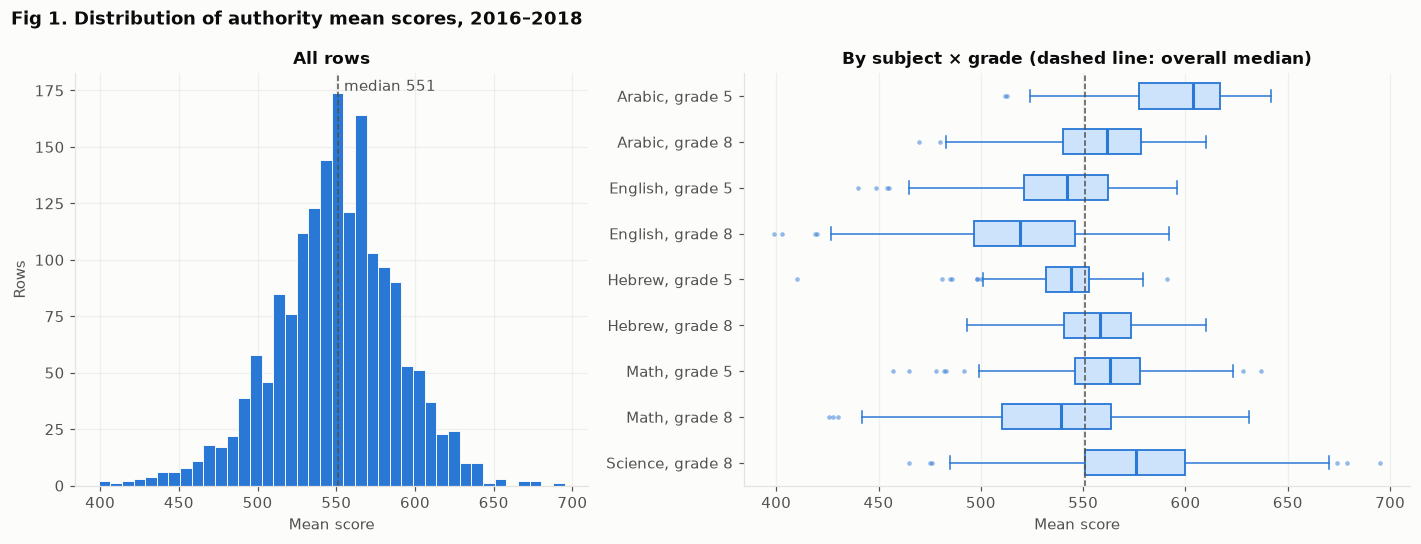

count   mean  median   std    min    max
subject_id shichva                                          
Arabic     5        106.0  593.9   603.5  30.7  512.0  642.0
           8        106.0  555.3   561.5  30.9  470.0  610.0
English    5        185.0  539.5   542.0  31.3  440.0  596.0
           8        268.0  517.9   519.0  37.0  399.0  592.0
Hebrew     5        190.0  540.6   544.0  19.9  410.0  591.0
           8        179.0  557.2   558.0  23.1  493.0  610.0
Math       5        186.0  559.6   563.0  29.5  457.0  637.0
           8        266.0  536.9   539.0  39.5  426.0  631.0
Science    8        263.0  575.2   576.0  37.9  465.0  695.0

In [292]:
fig, (ax_all, ax_grp) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 1.3]})
overall_median = data["score"].median()

ax_all.hist(data["score"], bins=40, color=BLUE, edgecolor=SURFACE, linewidth=0.6)
ax_all.axvline(overall_median, color=INK_MUTED, linestyle="--", linewidth=1)
ax_all.annotate(f"median {overall_median:.0f}", (overall_median, 1), xycoords=("data", "axes fraction"),
                xytext=(4, -4), textcoords="offset points", va="top", color=INK_MUTED)
ax_all.set(title="All rows", xlabel="Mean score", ylabel="Rows")

ax_grp.boxplot([rows_of(s, g)["score"] for s, g in GROUPS], orientation="horizontal",
               tick_labels=[GROUP_LABELS[k] for k in GROUPS], widths=0.55, **BOX_STYLE)
ax_grp.invert_yaxis()
ax_grp.axvline(overall_median, color=INK_MUTED, linestyle="--", linewidth=1)
ax_grp.set(title="By subject × grade (dashed line: overall median)", xlabel="Mean score")
ax_grp.grid(axis="y", visible=False)
fig.suptitle("Fig 1. Distribution of authority mean scores, 2016–2018", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

score_by_group = (data.groupby(["subject_id", "shichva"])["score"]
                  .describe()[["count", "mean", "50%", "std", "min", "max"]]
                  .rename(columns={"50%": "median"}).rename(index=SUBJECT_NAMES, level=0).round(1))
score_by_group

**Fig 1.** Pooled together, scores look roughly bell-shaped around a median of 551. But the subject × grade
groups sit at very different levels: medians run from 519 (English, grade 8) to 604 (Arabic, grade 5), and
spreads run from an SD of 20 (Hebrew, grade 5) to 40 (Math, grade 8). With one pooled median as the high/low
cut-off, 87% of Arabic grade 5 rows would be "high" and only 18% of English grade 8 rows. The label would
mostly record which test a row is, not how the authority did. So the high/low label has to be set **within each
subject × grade**.

### Score against number of students tested

A mean computed from a handful of students swings much more than one computed from hundreds. To see how far
this goes, we plot score against the number of students tested (log scale), count the small cells, and measure
the spread of scores in each size band. The spread is measured as the standard deviation of each row's distance
from its own subject × grade mean, so the differences in level between subjects don't inflate it.

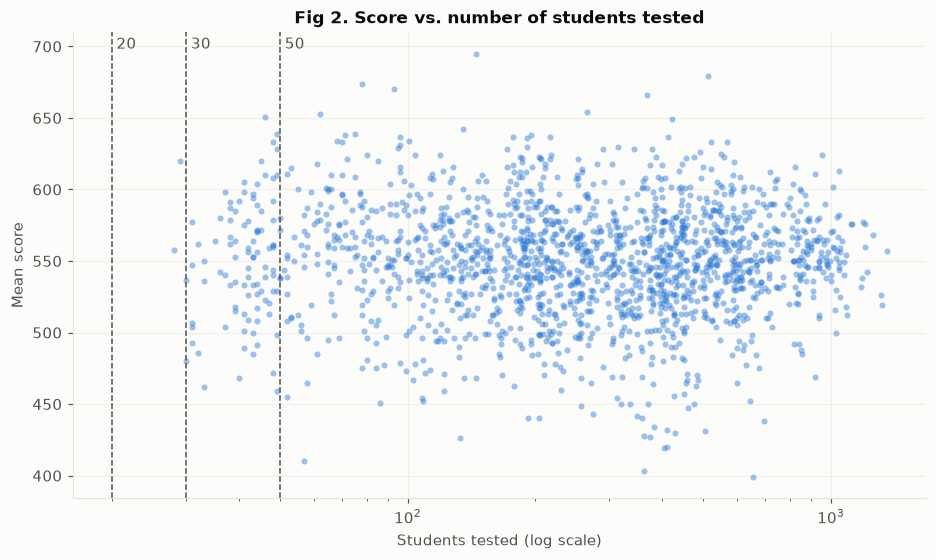

,rows,% of rows,authorities
under 20,0.0,0.0,0.0
under 30,2.0,0.1,2.0
under 50,96.0,5.5,24.0


,rows,SD of distance from subject × grade mean
n_students_tested,,
20–29,2,19.6
30–49,94,35.8
50–99,186,37.2
100–199,381,30.2
200+,1086,32.3


In [293]:
SMALL_CELL_CUTOFFS = [20, 30, 50]
n_tested = data["n_students_tested"]

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.scatter(n_tested, data["score"], s=16, color=BLUE, alpha=0.45, linewidths=0)
ax.set_xscale("log")
for cutoff in SMALL_CELL_CUTOFFS:
    ax.axvline(cutoff, color=INK_MUTED, linestyle="--", linewidth=1)
    ax.annotate(str(cutoff), (cutoff, 1), xycoords=("data", "axes fraction"), xytext=(3, -3),
                textcoords="offset points", va="top", color=INK_MUTED)
ax.set(xlabel="Students tested (log scale)", ylabel="Mean score",
       title="Fig 2. Score vs. number of students tested")
plt.show()

small_cells = pd.DataFrame({
    f"under {cutoff}": {
        "rows": (n_tested < cutoff).sum(),
        "% of rows": round((n_tested < cutoff).mean() * 100, 1),
        "authorities": data.loc[n_tested < cutoff, "rashut"].nunique(),
    }
    for cutoff in SMALL_CELL_CUTOFFS
}).T
display(small_cells)

distance_from_group_mean = data["score"] - data.groupby(["subject_id", "shichva"])["score"].transform("mean")
size_band = pd.cut(n_tested, [0, 20, 30, 50, 100, 200, np.inf], right=False,
                   labels=["<20", "20–29", "30–49", "50–99", "100–199", "200+"])
distance_from_group_mean.groupby(size_band, observed=True).agg(["count", "std"]).round(1).rename(
    columns={"count": "rows", "std": "SD of distance from subject × grade mean"})

**Fig 2.** Once rows without a score are gone, the very small cells are gone too. No row has under 20 students
tested, 2 rows have under 30, and 96 rows (5.5%, from 24 authorities) have under 50. The Ministry evidently
doesn't publish a score for very small groups (see the next table). There's no clear funnel either: scores in
the 30–49 band spread about as much as in the 200+ band (SD 35.8 vs 32.3 around the subject × grade mean). A
cut-off at 30 would remove only 2 rows, so the small-cell problem is mostly handled by the Ministry's own
suppression. Weighting by `n_students_tested` in the models is still reasonable, but it will matter less than
expected.

### Rows with no score: small samples or one sector?

The 44 rows with no score were already taken out in the cleaning step (`rows_without_score` holds them). Here
we check whether they are random or follow a pattern. We compare the share of missing scores by size band and
by sector, out of all rows before the drop.

In [294]:
before_drop = pd.concat([
    data[["norm_id", "n_students_tested"]].assign(missing_score=False),
    rows_without_score[["norm_id", "n_students_tested"]].assign(missing_score=True),
])
before_size_band = pd.cut(before_drop["n_students_tested"], [0, 20, 30, 50, np.inf], right=False,
                          labels=["<20", "20–29", "30–49", "50+"])

def missing_share(by):
    table = before_drop.groupby(by, observed=True)["missing_score"].agg(rows="size", missing_score="sum")
    table["% missing"] = (table["missing_score"] / table["rows"] * 100).round(1)
    return table

print("By number of students tested:")
display(missing_share(before_size_band))
print("By sector:")
display(missing_share(before_drop["norm_id"].map(SECTOR_NAMES)))

assert data["score"].notna().all(), "the analysis table should have no missing scores"
print(f"Rows with no score dropped: {len(rows_without_score)}; analysis table: {len(data)} rows")

By number of students tested:


,rows,missing_score,% missing
n_students_tested,,,
<20,25,25,100.0
20–29,17,15,88.2
30–49,95,1,1.1
50+,1656,3,0.2


By sector:


,rows,missing_score,% missing
norm_id,,,
Arabic-language,561,4,0.7
Hebrew-language,1025,35,3.4
combined,207,5,2.4


Rows with no score dropped: 44; analysis table: 1749 rows


**Missing scores follow group size, not sector.** All 25 rows with under 20 students tested and 15 of the 17
rows with 20–29 have no score. Above 30 students only 4 of 1,751 rows (0.2%) are missing. The Hebrew-language
sector has a higher missing rate (3.4% vs 0.7%) only because it has more small groups. Every one of its missing
rows has under 30 students tested. So the missing scores are not random: they are the smallest groups, held back
by the Ministry. They can't be filled in and were dropped (44 rows). The cost is that the smallest authorities
are under-represented, which belongs in the limitations.

### Score by socio-economic cluster, per subject × grade

This section checks the relationship the project is built on: do authorities in higher socio-economic clusters
score higher? Each subject × grade gets its own panel, because they sit at different levels (Fig 1). Spearman ρ
measures how consistently scores rise with the cluster. It ranks the values instead of using them directly, so
it does not assume the rise is a straight line. The gradient itself is already well documented, so we confirm
it here as a baseline rather than present it as a finding of our own.

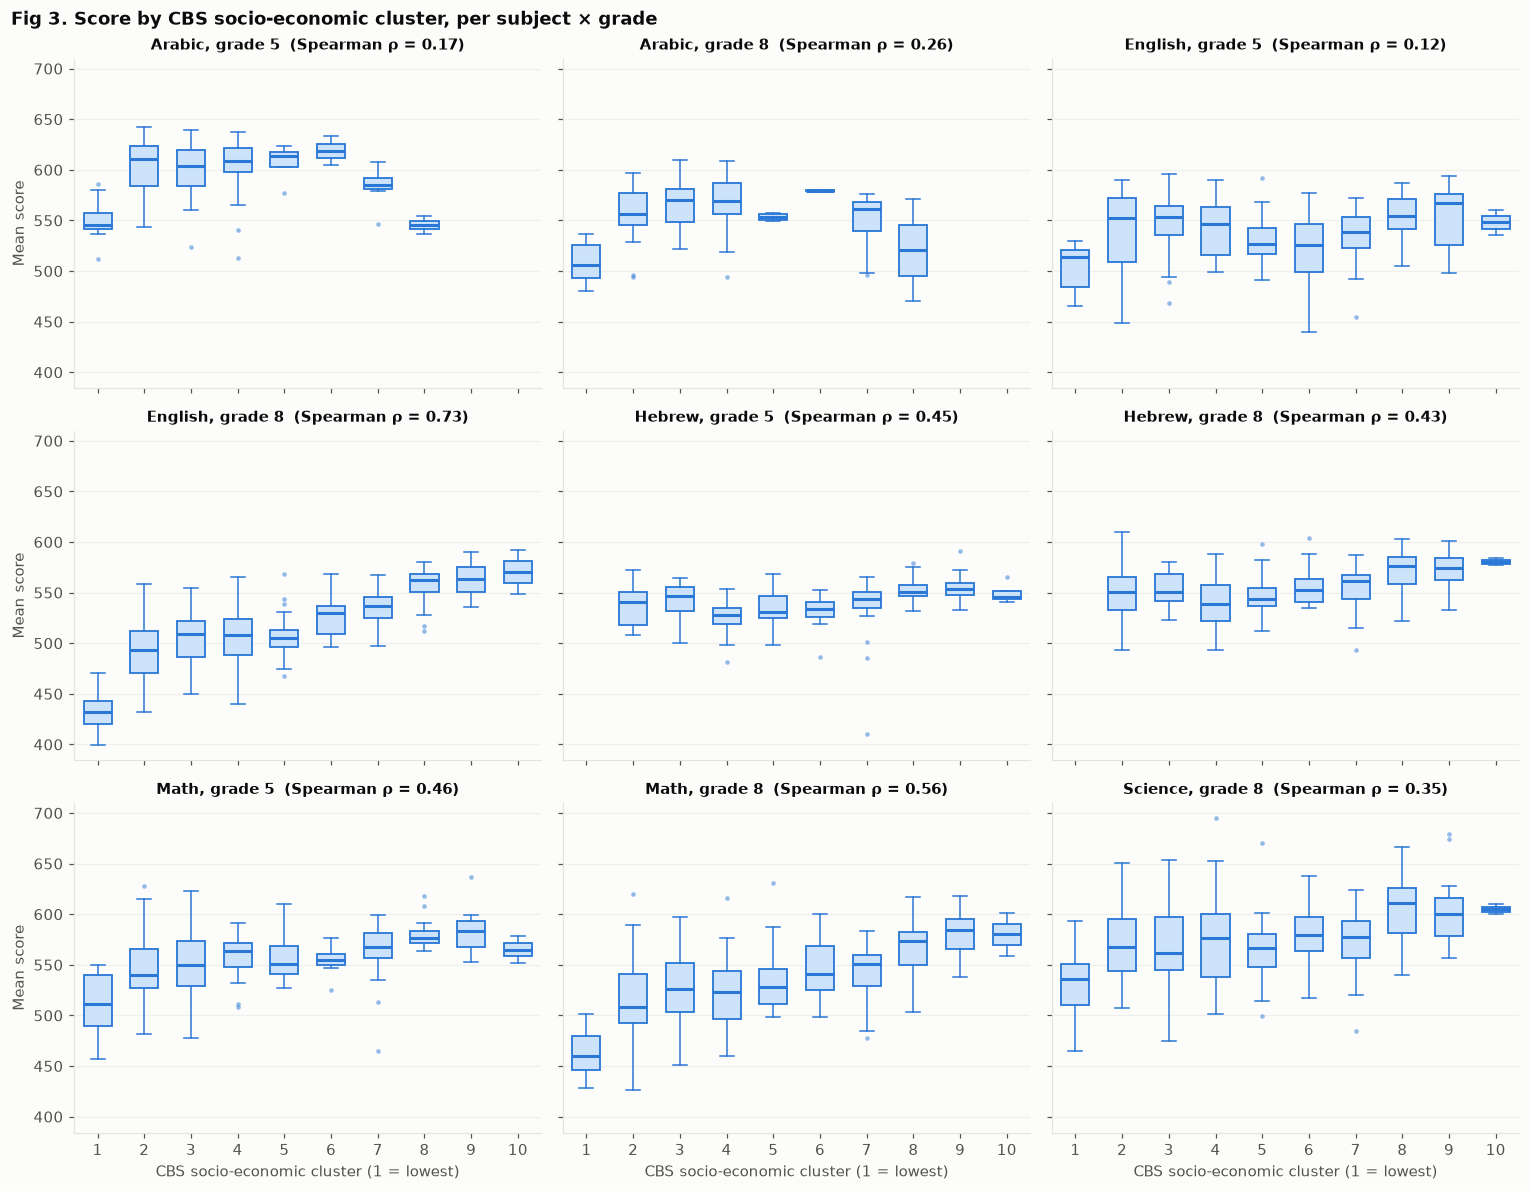

In [295]:
CLUSTERS = range(1, 11)
fig, axes = plt.subplots(3, 3, figsize=(14, 11), sharex=True, sharey=True)

for ax, (subject, grade) in zip(axes.flat, GROUPS):
    rows = rows_of(subject, grade)
    present = [c for c in CLUSTERS if (rows["ses_cluster"] == c).any()]
    ax.boxplot([rows.loc[rows["ses_cluster"] == c, "score"] for c in present], positions=present,
               widths=0.6, **BOX_STYLE)
    rho = rows["ses_cluster"].rank().corr(rows["score"].rank())  # Spearman = Pearson on ranks (no scipy needed)
    ax.set_title(f"{GROUP_LABELS[(subject, grade)]}  (Spearman ρ = {rho:.2f})", fontsize=10)
    ax.set_xticks(list(CLUSTERS), [str(c) for c in CLUSTERS])
    ax.grid(axis="x", visible=False)

for ax in axes[-1]:
    ax.set_xlabel("CBS socio-economic cluster (1 = lowest)")
for ax in axes[:, 0]:
    ax.set_ylabel("Mean score")
fig.suptitle("Fig 3. Score by CBS socio-economic cluster, per subject × grade", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout()
plt.show()

**Fig 3.** Scores rise with socio-economic cluster in most subject × grade groups. The gradient is strongest in
English grade 8 (Spearman ρ = 0.73) and Math grade 8 (0.56), weaker in Hebrew (about 0.45), and weakest in
English grade 5 (0.12). The Arabic panels rise and then fall, which comes from a **sector overlap** rather than
from socio-economic level. Arabic is tested only in Arabic-language schools. Clusters 1–3 are almost all
Arabic-language authorities (cluster 1 is the Negev Bedouin towns), and the few Arabic rows in clusters 7–8 come
from mixed authorities such as Haifa, Tel Aviv-Yafo and Misgav. The same overlap runs through the other subjects:
low clusters are mostly Arabic-language authorities and high clusters mostly Hebrew-language ones. Part of
any "cluster effect" is therefore a sector effect, so sector (`norm_id`) has to be in the models alongside the
index. Clusters 1 and 10 also hold few authorities (9 and 4), so their boxes are based on few points.

### Score against the continuous socio-economic index

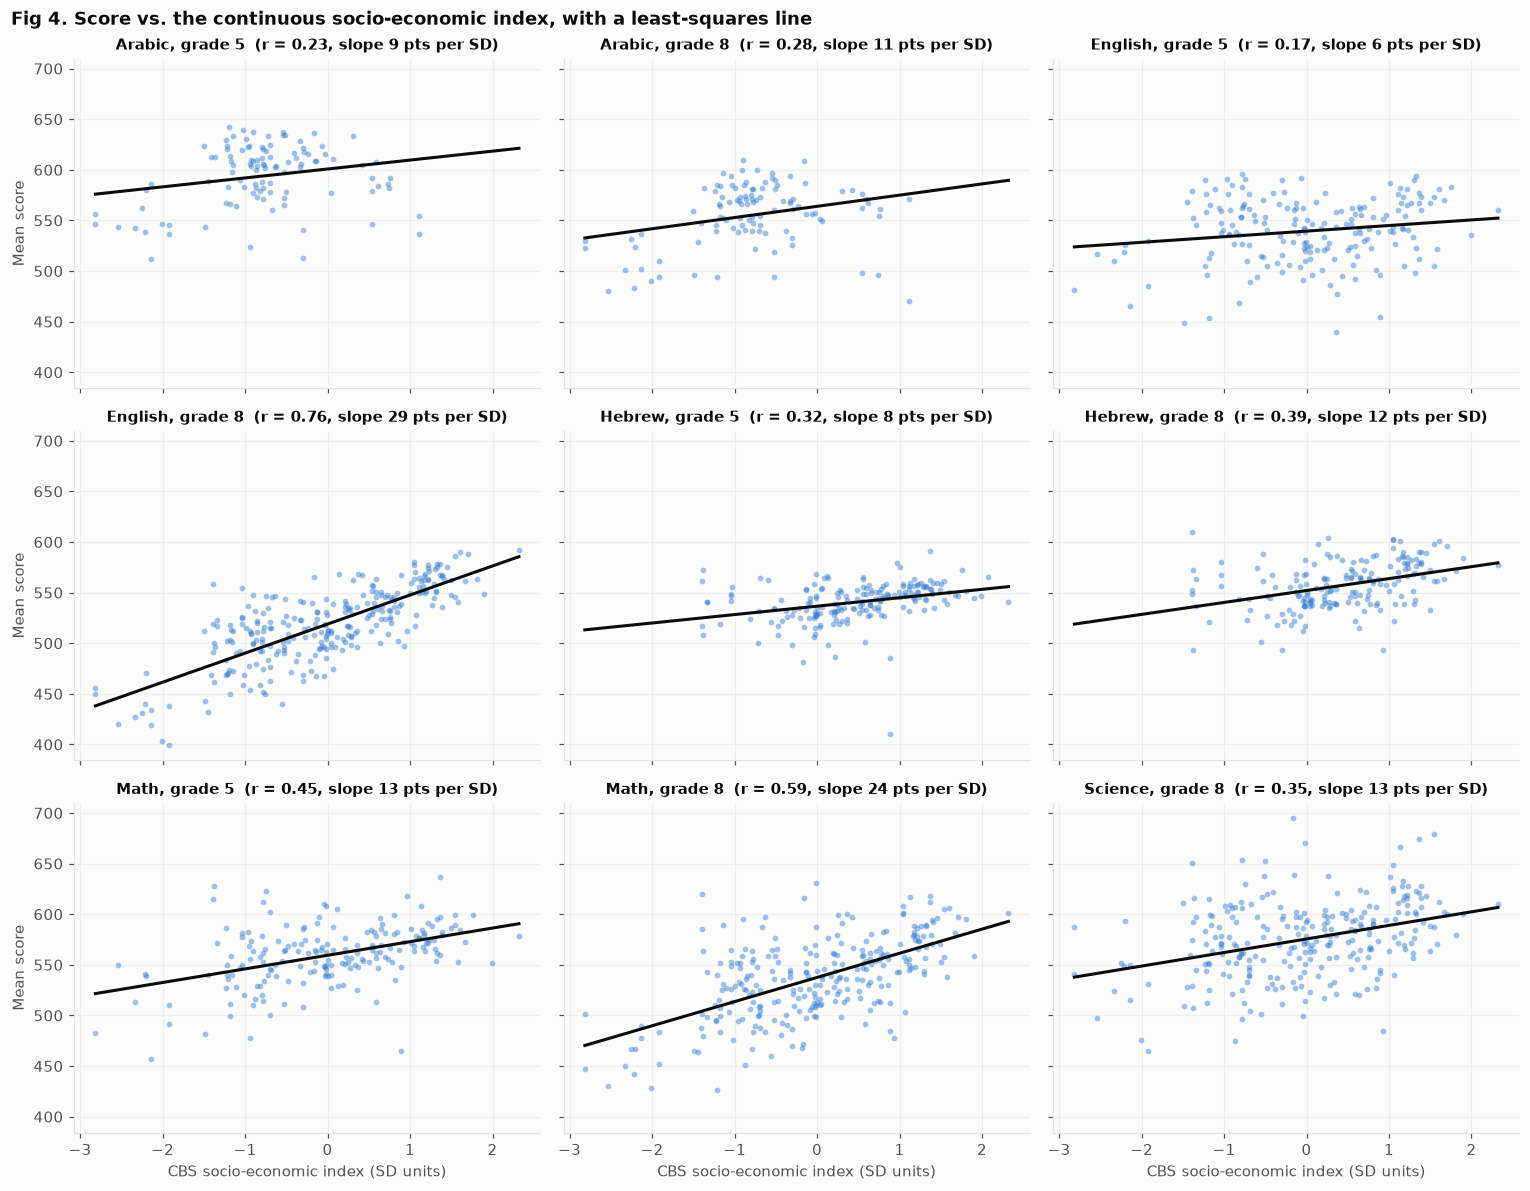

In [296]:
fig, axes = plt.subplots(3, 3, figsize=(14, 11), sharex=True, sharey=True)
index_grid = np.linspace(data["ses_index"].min(), data["ses_index"].max(), 50)

for ax, (subject, grade) in zip(axes.flat, GROUPS):
    rows = rows_of(subject, grade)
    ax.scatter(rows["ses_index"], rows["score"], s=14, color=BLUE, alpha=0.45, linewidths=0)
    slope, intercept = np.polyfit(rows["ses_index"], rows["score"], 1)
    ax.plot(index_grid, intercept + slope * index_grid, color=INK, linewidth=2)
    r = rows["ses_index"].corr(rows["score"])
    ax.set_title(f"{GROUP_LABELS[(subject, grade)]}  (r = {r:.2f}, slope {slope:.0f} pts per SD)", fontsize=10)

for ax in axes[-1]:
    ax.set_xlabel("CBS socio-economic index (SD units)")
for ax in axes[:, 0]:
    ax.set_ylabel("Mean score")
fig.suptitle("Fig 4. Score vs. the continuous socio-economic index, with a least-squares line",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

**Fig 4.** The continuous index shows the same picture. The relationship is strongest in English grade 8
(r = 0.76, about 29 points per SD of the index) and Math grade 8 (r = 0.59, 24 points), and weak in grade 5 and in
Arabic (r = 0.17–0.28). So the index explains a lot in some tests and little in others. That's why the gaps
between actual and predicted scores, the core of the project, should be computed within subject × grade. Points
far above or below the line at the same index value are the over- and under-performers we're looking for.

### Correlations between the CBS variables

The CBS variables describe authorities, not test rows, so we compute the correlations on one row per
authority. Otherwise authorities with more tested subjects would count more.

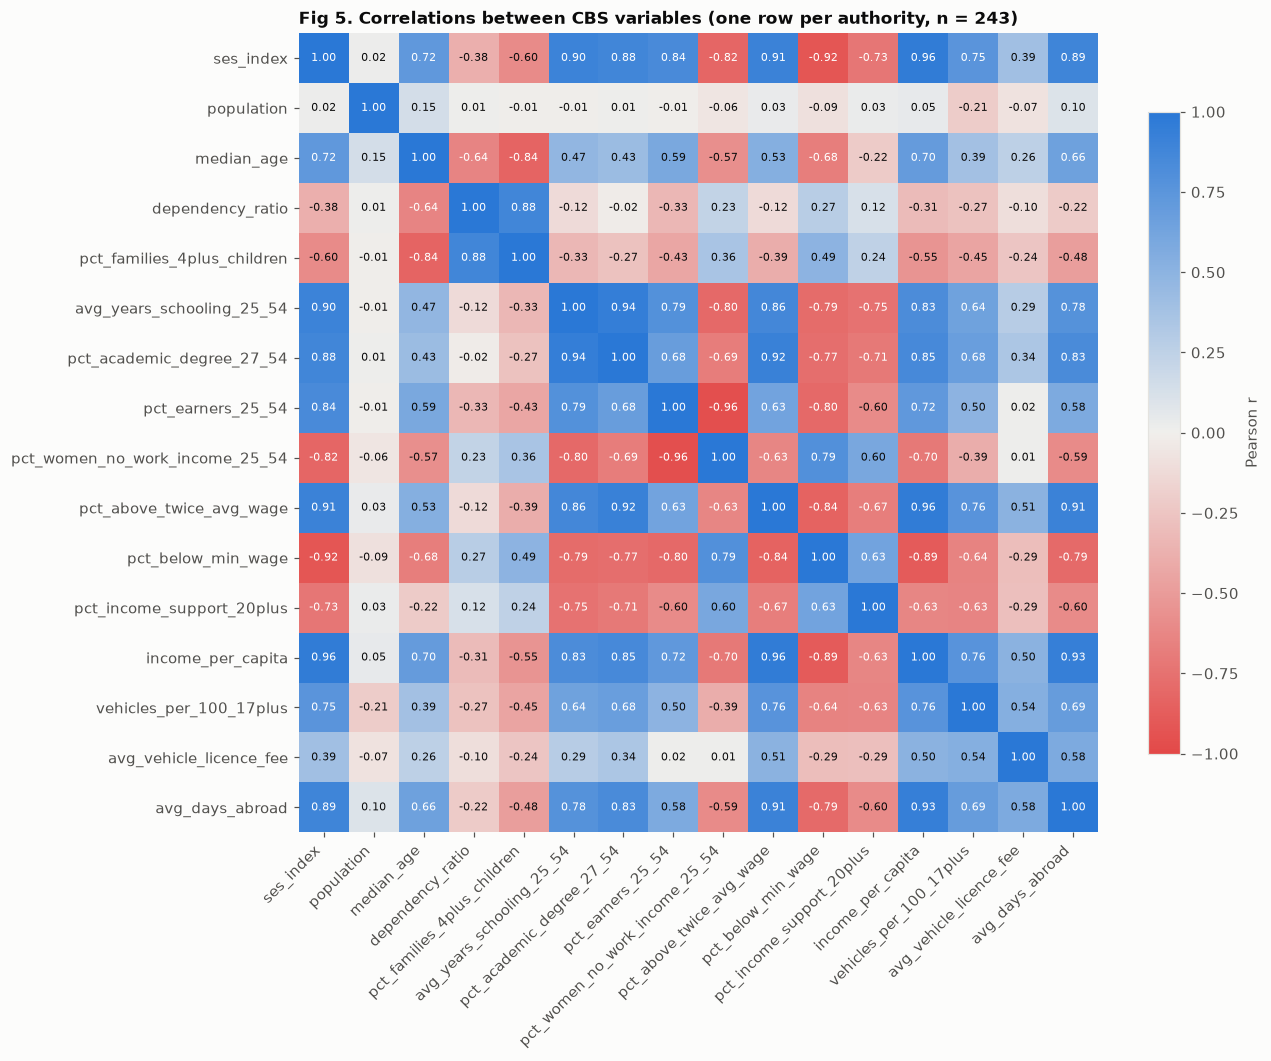

Variable pairs with |r| > 0.8: 23 of 120

Correlation of each variable with ses_index:
income_per_capita                 0.96
pct_below_min_wage               -0.92
pct_above_twice_avg_wage          0.91
avg_years_schooling_25_54         0.90
avg_days_abroad                   0.89
pct_academic_degree_27_54         0.88
pct_earners_25_54                 0.84
pct_women_no_work_income_25_54   -0.82
vehicles_per_100_17plus           0.75
pct_income_support_20plus        -0.73
median_age                        0.72
pct_families_4plus_children      -0.60
avg_vehicle_licence_fee           0.39
dependency_ratio                 -0.38
population                        0.02


In [297]:
CBS_FEATURES = ["ses_index", "population"] + CBS_VARIABLES
cbs_corr = data.drop_duplicates("rashut")[CBS_FEATURES].corr()

diverging = LinearSegmentedColormap.from_list("red_gray_blue", [RED, NEUTRAL, BLUE])
fig, ax = plt.subplots(figsize=(12, 10))
image = ax.imshow(cbs_corr, cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(len(CBS_FEATURES)), CBS_FEATURES, rotation=45, ha="right")
ax.set_yticks(range(len(CBS_FEATURES)), CBS_FEATURES)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
for i in range(len(CBS_FEATURES)):
    for j in range(len(CBS_FEATURES)):
        r = cbs_corr.iat[i, j]
        ax.text(j, i, f"{r:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(r) > 0.6 else INK)
fig.colorbar(image, ax=ax, shrink=0.75, label="Pearson r")
ax.set_title(f"Fig 5. Correlations between CBS variables (one row per authority, n = {data['rashut'].nunique()})",
             loc="left")
fig.tight_layout()
plt.show()

upper = cbs_corr.where(np.triu(np.ones(cbs_corr.shape, dtype=bool), k=1)).stack().dropna()
print(f"Variable pairs with |r| > 0.8: {(upper.abs() > 0.8).sum()} of {len(upper)}")
print()
print("Correlation of each variable with ses_index:")
print(cbs_corr["ses_index"].drop("ses_index").sort_values(key=abs, ascending=False).round(2).to_string())

**Fig 5.** The CBS variables are strongly correlated with each other. `ses_index` correlates above 0.8 with
eight of them, led by income per capita (0.96), the share earning below minimum wage (−0.92) and the share earning
above twice the average wage (0.91). The schooling and degree variables (0.90 and 0.88) are among the inputs the
CBS uses to build the index, so they partly *are* the index. Two consequences follow. A linear model that uses
`ses_index` and these variables together will have unstable coefficients. And Random Forest feature importances
will be split arbitrarily between near-duplicates, so they can't be read as independent effects. `population`
is the one variable unrelated to the index (r = 0.02), and `avg_vehicle_licence_fee` and `dependency_ratio` are
only weakly related.

In [298]:
# The cleaned analysis table, saved so it can be looked through in Excel
data.to_excel(Path("data") / "cleaned_dataset.xlsx", index=False)

print(f"Analysis table: {len(data)} rows, {data.shape[1]} columns, {data['rashut'].nunique()} authorities")

Analysis table: 1749 rows, 29 columns, 243 authorities


# Model Building

## Train / validation / test split by authority

Our rows are not independent. The analysis table has 1,749 rows from only 243 authorities, and each authority
appears up to 25 times (once per year, grade and subject). If we split by row, the same authority would sit in
both the training and the test set. A model could then learn that authority's typical score and look accurate on
the test set without having learned anything that carries over to a new authority. So we split by **authority**
(`rashut`): every row of an authority goes to the same set.

We use `GroupShuffleSplit` with `rashut` as the group, holding out about 30% of the authorities for test and 20%
for validation, which leaves about 50% for training. Cluster 10 has only 4 authorities and cluster 1 has 9, so one
split over the whole table can easily leave a cluster out of the validation or test set. We therefore run the split
**inside each cluster** and combine the parts. That stratifies by cluster: every cluster appears in all three sets.
Because authorities contribute different numbers of rows, the shares by row will differ from the shares by
authority, so we report both.

In [299]:
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, train_test_split

TEST_SHARE, VAL_SHARE = 0.3, 0.2  # shares of authorities; training gets the remaining ~50%

def hold_out_authorities(rows, n_out, seed=RANDOM_STATE):
    # GroupShuffleSplit with rashut as the group: n_out whole authorities go to the second part
    splitter = GroupShuffleSplit(n_splits=1, test_size=n_out, random_state=seed)
    keep, out = next(splitter.split(rows, groups=rows["rashut"]))
    return rows.iloc[keep], rows.iloc[out]

# Split each cluster separately so that every cluster, even cluster 10 with 4 authorities, lands in all three sets
parts = {"train": [], "validation": [], "test": []}
for cluster, rows in data.groupby("ses_cluster"):
    n_authorities = rows["rashut"].nunique()
    rest, test = hold_out_authorities(rows, max(1, round(TEST_SHARE * n_authorities)))
    train, validation = hold_out_authorities(rest, max(1, round(VAL_SHARE * n_authorities)))
    for name, part in [("train", train), ("validation", validation), ("test", test)]:
        parts[name].append(part)

SPLITS = {name: pd.concat(part_list).sort_index() for name, part_list in parts.items()}
train_set, val_set, test_set = SPLITS["train"], SPLITS["validation"], SPLITS["test"]

# Fail if an authority is in two sets, or if a row was lost or duplicated
authorities_in = {name: set(rows["rashut"]) for name, rows in SPLITS.items()}
shared = ((authorities_in["train"] & authorities_in["validation"]) | (authorities_in["train"] & authorities_in["test"])
          | (authorities_in["validation"] & authorities_in["test"]))
assert not shared, f"Authorities in more than one set: {sorted(shared)}"
assert sorted(np.concatenate([rows.index for rows in SPLITS.values()])) == sorted(data.index), "rows lost or duplicated"
print("No authority appears in more than one set.")

split_sizes = pd.DataFrame({
    name: {
        "rows": len(rows),
        "% of rows": round(100 * len(rows) / len(data), 1),
        "authorities": rows["rashut"].nunique(),
        "% of authorities": round(100 * rows["rashut"].nunique() / data["rashut"].nunique(), 1),
        "clusters": rows["ses_cluster"].nunique(),
    }
    for name, rows in SPLITS.items()
}).T.astype({"rows": int, "authorities": int, "clusters": int})
display(split_sizes)

authority_split = pd.concat([rows.drop_duplicates("rashut").assign(split=name) for name, rows in SPLITS.items()])
print("Authorities per cluster in each set:")
display(pd.crosstab(authority_split["ses_cluster"], authority_split["split"], margins=True, margins_name="total")
        [["train", "validation", "test", "total"]])

No authority appears in more than one set.


,rows,% of rows,authorities,% of authorities,clusters
train,840,48.0,121,49.8,10
validation,362,20.7,48,19.8,10
test,547,31.3,74,30.5,10


Authorities per cluster in each set:


split,train,validation,test,total
ses_cluster,,,,
1,4,2,3,9
2,11,4,7,22
3,22,9,13,44
4,16,6,10,32
5,14,5,8,27
6,11,4,7,22
7,19,8,11,38
8,9,4,6,19
9,13,5,8,26


**Table 4.** By authority the split is 50 / 20 / 30 (121 / 48 / 74 authorities). By row it comes out at
48 / 21 / 31 (840 / 362 / 547 rows), close to the target because the per-cluster splits even out the differences in
rows per authority. No authority is in two sets, and all 10 clusters appear in each set, including cluster 10
(2 / 1 / 1 authorities) and cluster 1 (4 / 2 / 3).

To check that stratifying was needed, we repeat the same 50/30/20 grouped split over the whole table, without
splitting by cluster first, for 1,000 different seeds and count how often a set ends up missing a cluster.

In [300]:
def misses_a_cluster(seed):
    rest, test = hold_out_authorities(data, TEST_SHARE, seed)
    train, validation = hold_out_authorities(rest, VAL_SHARE / (1 - TEST_SHARE), seed)
    return any(rows["ses_cluster"].nunique() < data["ses_cluster"].nunique() for rows in (train, validation, test))

N_SEEDS = 1000
missed = sum(misses_a_cluster(seed) for seed in range(N_SEEDS))
print(f"Unstratified grouped split: at least one set is missing a cluster in {missed} of {N_SEEDS} seeds "
      f"({100 * missed / N_SEEDS:.0f}%)")

Unstratified grouped split: at least one set is missing a cluster in 688 of 1000 seeds (69%)


Without stratifying, 69% of seeds leave at least one cluster out of a set, almost always cluster 10 or 1. With 4
authorities in cluster 10, a 20% validation set gets fewer than one of them on average. Splitting inside each
cluster removes this risk.

### Folds for tuning
Hyperparame
ters will be tuned by cross-validation on the training set. The folds have to respect authorities too,
otherwise the same leak comes back inside tuning. `GroupKFold` with `rashut` as the group puts each authority in
exactly one fold. `TUNING_CV` and `train_groups` are passed to `GridSearchCV` later (`cv=TUNING_CV`,
`groups=train_groups`). We use 5 fold because it's the conventional default.

In [301]:
TUNING_CV = GroupKFold(n_splits=5)
train_groups = train_set["rashut"]

fold_sizes = {}
for fold, (fit_idx, check_idx) in enumerate(TUNING_CV.split(train_set, groups=train_groups), start=1):
    fit_rows, check_rows = train_set.iloc[fit_idx], train_set.iloc[check_idx]
    assert not set(fit_rows["rashut"]) & set(check_rows["rashut"]), f"fold {fold} shares an authority"
    fold_sizes[f"fold {fold}"] = {
        "rows": len(check_rows),
        "authorities": check_rows["rashut"].nunique(),
        "clusters": check_rows["ses_cluster"].nunique(),
    }

print("No authority is in both the fitting and the checking part of any fold.")
print("Held-out part of each fold:")
display(pd.DataFrame(fold_sizes).T)

No authority is in both the fitting and the checking part of any fold.
Held-out part of each fold:


,rows,authorities,clusters
fold 1,169,24,8
fold 2,168,24,8
fold 3,168,25,9
fold 4,167,24,7
fold 5,168,24,8


Each fold holds out about 24 authorities (167–169 rows), and no authority is on both sides of a fold. Each held-out
fold covers 7 to 9 of the 10 clusters. That can't be fixed: the training set has only 2 authorities from cluster 10
and 4 from cluster 1, so they can't reach all 5 folds. The validation and test sets do cover every cluster, and
those are where results are reported.

### For comparison: a plain split by row

We also run the split the usual way once, by row with `train_test_split`, in the same 50/30/20 shares. We count how
many authorities end up in more than one set, and test the memorising shortcut directly: predict each test row
from the same authority's average in the training set, without any socio-economic variable. Scores are first
standardized within each subject × grade × year (using training-set means and SDs) so that rows from different
tests are comparable. Under the grouped split this shortcut is impossible, because no test authority has rows in
the training set.

In [302]:
row_rest, row_test = train_test_split(data, test_size=TEST_SHARE, random_state=RANDOM_STATE)
row_train, row_val = train_test_split(row_rest, test_size=VAL_SHARE / (1 - TEST_SHARE), random_state=RANDOM_STATE)
ROW_SPLITS = {"train": row_train, "validation": row_val, "test": row_test}

sets_per_authority = pd.concat([rows[["rashut"]].assign(split=name) for name, rows in ROW_SPLITS.items()]) \
    .groupby("rashut")["split"].nunique()
test_rows_seen = row_test["rashut"].isin(row_train["rashut"]).mean()
print(f"Row split: {(sets_per_authority > 1).sum()} of {len(sets_per_authority)} authorities appear in more than one set")
print(f"Row split: {100 * test_rows_seen:.0f}% of test rows belong to an authority that is also in the training set")

def standardized(rows, reference):
    # z-score within subject × grade × year, using the reference (training) rows' mean and SD
    keys = ["subject_id", "shichva", "year"]
    stats = reference.groupby(keys)["score"].agg(["mean", "std"])
    joined = rows.join(stats, on=keys)
    return (joined["score"] - joined["mean"]) / joined["std"]

train_z = standardized(row_train, row_train)
authority_mean_z = train_z.groupby(row_train["rashut"]).mean()
test_z = standardized(row_test, row_train)
predicted_z = row_test["rashut"].map(authority_mean_z).fillna(0)  # unseen authority: predict the average

r2 = 1 - ((test_z - predicted_z) ** 2).sum() / ((test_z - test_z.mean()) ** 2).sum()
print(f"Row split, predicting each test row from its authority's training average: R² = {r2:.2f}")
print(f"Grouped split: {test_set['rashut'].isin(train_set['rashut']).sum()} test rows belong to a training authority, "
      "so this shortcut is not available")

Row split: 236 of 243 authorities appear in more than one set
Row split: 97% of test rows belong to an authority that is also in the training set
Row split, predicting each test row from its authority's training average: R² = 0.30
Grouped split: 0 test rows belong to a training authority, so this shortcut is not available


**The difference.** In the plain row split, 236 of the 243 authorities land in more than one set, and 97% of test
rows belong to an authority the model has already seen in training. Predicting each test row from nothing but its
authority's training average already gives R² = 0.30, without a single socio-economic variable. In a row split, part of
any model's test accuracy would be this memorising, not a relationship that carries over to a new authority. In the
grouped split no test authority appears in training, so the shortcut isn't there. Later, the models will be scored
both ways. To show how much the row split flatters them. The grouped numbers are the ones we report.

## Predicting the score

How well can an authority's score be predicted? This matters because the over- and under-performers are
defined as the authorities a model *misses*. If the model predicted badly, every authority would look like an
outlier.

**Features (20).** 16 numbers describing the authority — `ses_index`, `population` and the 14 CBS variables —
plus 4 labels describing the test: grade, subject, sector and year. The labels are needed because scores sit at
different levels per subject × grade (Fig 1), sector overlaps with cluster (Fig 3), and scores drift between
2016 and 2018.

Left out: `ses_cluster` (the same measurement as `ses_index`, Fig 5), the test-administration columns
(`n_students_tested` is used as the row weight instead), and `rashut` — feeding in the authority id would be
the memorising shortcut the grouped split just removed.

**Missing values.** The 3 authorities with suppressed CBS variables are filled with the median *inside the
pipeline*, so the median comes from the training rows only. Dropping them would thin out the upper clusters.

**Protocol.** Fit on training, compare on validation, open the test set once at the end for the winner.

In [303]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

NUMERIC_FEATURES = ["ses_index", "population"] + CBS_VARIABLES
CATEGORICAL_FEATURES = ["shichva", "subject_id", "norm_id", "year"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET, WEIGHT = "score", "n_students_tested"

def features_target_weight(rows):
    return rows[FEATURES], rows[TARGET], rows[WEIGHT].to_numpy(float)

X_train, y_train, w_train = features_target_weight(train_set)
X_val, y_val, w_val = features_target_weight(val_set)
X_test, y_test, w_test = features_target_weight(test_set)

def make_pipeline(model, drop_first):
    # Both preprocessing steps learn their numbers inside the pipeline, so in cross-validation they
    # only ever see the fitting fold. The median fills the suppressed CBS variables.
    # drop_first removes one dummy per categorical variable: needed for the linear model, which would
    # otherwise have a redundant column per variable alongside the intercept; the forest doesn't care.
    numeric = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    categorical = OneHotEncoder(drop="first" if drop_first else None, handle_unknown="ignore")
    preprocess = ColumnTransformer([("num", numeric, NUMERIC_FEATURES),
                                    ("cat", categorical, CATEGORICAL_FEATURES)])
    return Pipeline([("prep", preprocess), ("model", model)])

# Every model's validation numbers land here, so they can be compared in one table
results, val_predictions = [], {}

def record(name, fitted_on, y_true, prediction, weights):
    results.append({
        "model": name,
        "fitted on": fitted_on,
        "R2": r2_score(y_true, prediction),
        "RMSE": mean_squared_error(y_true, prediction) ** 0.5,
        "MAE": mean_absolute_error(y_true, prediction),
        "R2 weighted": r2_score(y_true, prediction, sample_weight=weights),
    })
    return prediction

def results_table():
    return pd.DataFrame(results).set_index(["model", "fitted on"]).round(3)

print(f"{len(FEATURES)} features: {len(NUMERIC_FEATURES)} numeric + {len(CATEGORICAL_FEATURES)} categorical")
print(f"Rows - train {len(X_train)}, validation {len(X_val)}, test {len(X_test)}")
print("Rows whose CBS variables are suppressed (median-imputed in the pipeline):",
      {name: int(X[CBS_VARIABLES].isna().any(axis=1).sum())
       for name, X in [("train", X_train), ("validation", X_val), ("test", X_test)]})

20 features: 16 numeric + 4 categorical
Rows - train 840, validation 362, test 547
Rows whose CBS variables are suppressed (median-imputed in the pipeline): {'train': 1, 'validation': 1, 'test': 4}


### Two baselines

To judge a model we first need to know what counts as doing well.

1. **Overall mean** — always guess the average training score. This is the floor. Its R² is not exactly 0
   because it uses the *training* mean, not the validation mean.
2. **Subject × grade mean** — guess the average for that subject and grade, and nothing else. This is the one
   that matters: Fig 1 showed most of the variation in `score` is just the difference between tests, so a model
   that cannot beat it has learned nothing about authorities.

In [304]:
overall_mean = y_train.mean()
GROUP_KEYS = ["subject_id", "shichva"]
group_mean = train_set.groupby(GROUP_KEYS)[TARGET].mean()

def predict_overall_mean(X):
    return np.full(len(X), overall_mean)

def predict_group_mean(X):
    # A subject x grade missing from the training set would fall back to the overall mean
    return X.join(group_mean.rename("group_mean"), on=GROUP_KEYS)["group_mean"].fillna(overall_mean).to_numpy()

record("Baseline: overall mean", "-", y_val, predict_overall_mean(X_val), w_val)
record("Baseline: subject x grade mean", "-", y_val, predict_group_mean(X_val), w_val)

print(f"Overall training mean: {overall_mean:.1f} points")
print("Training mean per subject x grade:")
display(group_mean.rename(index=SUBJECT_NAMES, level=0).round(1).to_frame("mean score"))
results_table()

Overall training mean: 549.7 points
Training mean per subject x grade:


mean score
subject_id shichva            
Arabic     5             592.8
           8             553.7
English    5             539.9
           8             518.2
Hebrew     5             540.4
           8             558.9
Math       5             559.3
           8             538.0
Science    8             575.7

,,R2,RMSE,MAE,R2 weighted
model,fitted on,,,,
Baseline: overall mean,-,-0.017,40.248,31.067,-0.012
Baseline: subject x grade mean,-,0.297,33.458,25.978,0.325


**The bar to clear.** Guessing the overall mean gives R² = −0.02 and misses by 31 points on average. Knowing
only the subject and grade raises R² to **0.30** and brings the miss down to 26 points. So about a third of the
variation is the difference between tests. That 0.30 is the number the real models have to beat.

### Linear regression

`LinearRegression` on the 16 numeric features plus dummies for grade, subject, sector and year. The features
are on very different scales (`population` in people, `ses_index` in SD units), so they need the
`StandardScaler` — and because it sits inside the pipeline, it learns its means and SDs from training rows only.

We fit it twice: once with every row counting equally, once **weighted by `n_students_tested`**, so a score
from 1,000 students counts more than one from 20. `R² weighted` applies the weights to the scoring as well.

We do not read the coefficients. Fig 5 showed `ses_index` correlates above 0.8 with eight of the CBS variables,
which makes them unstable.

In [305]:
for fitted_on, weights in [("unweighted", None), ("weighted by students tested", w_train)]:
    linear = make_pipeline(LinearRegression(), drop_first=True)
    linear.fit(X_train, y_train, model__sample_weight=weights)
    prediction = record("Linear regression", fitted_on, y_val, linear.predict(X_val), w_val)
    if weights is None:
        val_predictions["Linear regression"] = prediction
        linear_model = linear

print("Columns after preprocessing:", linear_model[:-1].transform(X_train).shape[1])
results_table()

Columns after preprocessing: 25


R2    RMSE  \
model                          fitted on                                    
Baseline: overall mean         -                           -0.017  40.248   
Baseline: subject x grade mean -                            0.297  33.458   
Linear regression              unweighted                   0.364  31.834   
                               weighted by students tested  0.271  34.060   

                                                               MAE  \
model                          fitted on                             
Baseline: overall mean         -                            31.067   
Baseline: subject x grade mean -                            25.978   
Linear regression              unweighted                   24.589   
                               weighted by students tested  26.039   

                                                            R2 weighted  
model                          fitted on                                 
Baseline: overall mean         -                                 -0.012  
Baseline: subject x grade mean -                                  0.325  
Linear regression              unweighted                         0.357  
                               weighted by students tested        0.242

**Result.** Unweighted, R² = 0.364 against the baseline's 0.297 — a real but modest gain. The 16
socio-economic variables buy about 7 points of R² and take the average miss from 26.0 to 24.6 points.

Weighting makes it **worse** (0.271, below the baseline). It pulls the fit towards the large authorities, and
there are few of them. It is worse on the weighted scoring too (0.242 vs 0.357), so this is not a scoring
artefact.

### Random forest

A forest can catch interactions the linear model cannot — for example that the index matters far more in
English grade 8 than in Arabic grade 5 (Fig 4).

Tuning has to respect authorities for the same reason the split does: with ordinary K-fold an authority would
land on both sides of a fold and the scores would be inflated. So `GridSearchCV` gets `TUNING_CV`
(`GroupKFold(5)` on `rashut`, cell 66) and `train_groups`.

The grid covers the three settings that control overfitting: tree depth, minimum rows per leaf, and features
per split. `n_estimators` is fixed at 400 rather than tuned — more trees only cost time.

In [306]:
PARAM_GRID = {
    "model__max_depth": [None, 8, 16],
    "model__min_samples_leaf": [1, 3, 10],
    "model__max_features": ["sqrt", 0.3, 1.0],
}

rf_search = {}
for fitted_on, weights in [("unweighted", None), ("weighted by students tested", w_train)]:
    forest = RandomForestRegressor(n_estimators=400, random_state=RANDOM_STATE, n_jobs=-1)
    search = GridSearchCV(make_pipeline(forest, drop_first=False), PARAM_GRID,
                          cv=TUNING_CV, scoring="r2")
    fit_params = {"groups": train_groups}
    if weights is not None:
        fit_params["model__sample_weight"] = weights
    search.fit(X_train, y_train, **fit_params)
    rf_search[fitted_on] = search

tuning = pd.DataFrame({
    fitted_on: {**{key.removeprefix("model__"): str(value) for key, value in search.best_params_.items()},
                "CV R2 (best)": round(search.best_score_, 3),
                "CV R2 (worst in grid)": round(search.cv_results_["mean_test_score"].min(), 3)}
    for fitted_on, search in rf_search.items()
}).T
display(tuning)

,max_depth,max_features,min_samples_leaf,CV R2 (best),CV R2 (worst in grid)
unweighted,None,sqrt,1,0.523,0.405
weighted by students tested,16,1.0,1,0.529,0.379


**What tuning bought.** Across the 27 settings the grouped-CV R² runs from 0.405 to 0.523, so the choice is
worth about 12 points. The winner is an unrestricted forest that looks at only `sqrt` of the features at each
split. That is the usual answer when features are correlated (Fig 5): it stops every tree from reaching for
`income_per_capita` first, so the trees end up different from each other. Sklearn's default (all features)
scores 0.500.

In [307]:
for fitted_on, search in rf_search.items():
    prediction = record("Random forest", fitted_on, y_val, search.best_estimator_.predict(X_val), w_val)
    if fitted_on == "unweighted":
        val_predictions["Random forest"] = prediction

results_table()

R2    RMSE  \
model                          fitted on                                    
Baseline: overall mean         -                           -0.017  40.248   
Baseline: subject x grade mean -                            0.297  33.458   
Linear regression              unweighted                   0.364  31.834   
                               weighted by students tested  0.271  34.060   
Random forest                  unweighted                   0.463  29.242   
                               weighted by students tested  0.413  30.580   

                                                               MAE  \
model                          fitted on                             
Baseline: overall mean         -                            31.067   
Baseline: subject x grade mean -                            25.978   
Linear regression              unweighted                   24.589   
                               weighted by students tested  26.039   
Random forest                  unweighted                   22.020   
                               weighted by students tested  22.655   

                                                            R2 weighted  
model                          fitted on                                 
Baseline: overall mean         -                                 -0.012  
Baseline: subject x grade mean -                                  0.325  
Linear regression              unweighted                         0.357  
                               weighted by students tested        0.242  
Random forest                  unweighted                         0.507  
                               weighted by students tested        0.455

**Table 5. Validation results.** The ranking is the same on all four measures:

| | R² | RMSE | MAE |
|---|---|---|---|
| Overall mean | −0.017 | 40.2 | 31.1 |
| Subject × grade mean | 0.297 | 33.5 | 26.0 |
| Linear regression | 0.364 | 31.8 | 24.6 |
| **Random forest** | **0.463** | **29.2** | **22.0** |

The forest wins: R² = 0.463, an average miss of 22.0 points. It removes about a quarter of the variation the
subject × grade baseline left unexplained, and beats the linear model by 10 points of R² — so the relationship
bends and interacts rather than running straight.

**Weighting does not help either model** (forest 0.463 → 0.413, linear 0.364 → 0.271). It wins only in
cross-validation (0.529 vs 0.523), and that reverses on held-out authorities, so it is noise. This is what
Fig 2 predicted: the Ministry already suppresses very small groups, so there was little instability left to
fix. We carry the **unweighted forest** forward.

### Residuals

R² says how much a model misses; the residuals say *where*. That matters here because the residuals are the
raw material of the main question — an authority scoring far above its prediction is what we mean by an
over-performer. First we have to check they are noise, not a pattern the model missed.

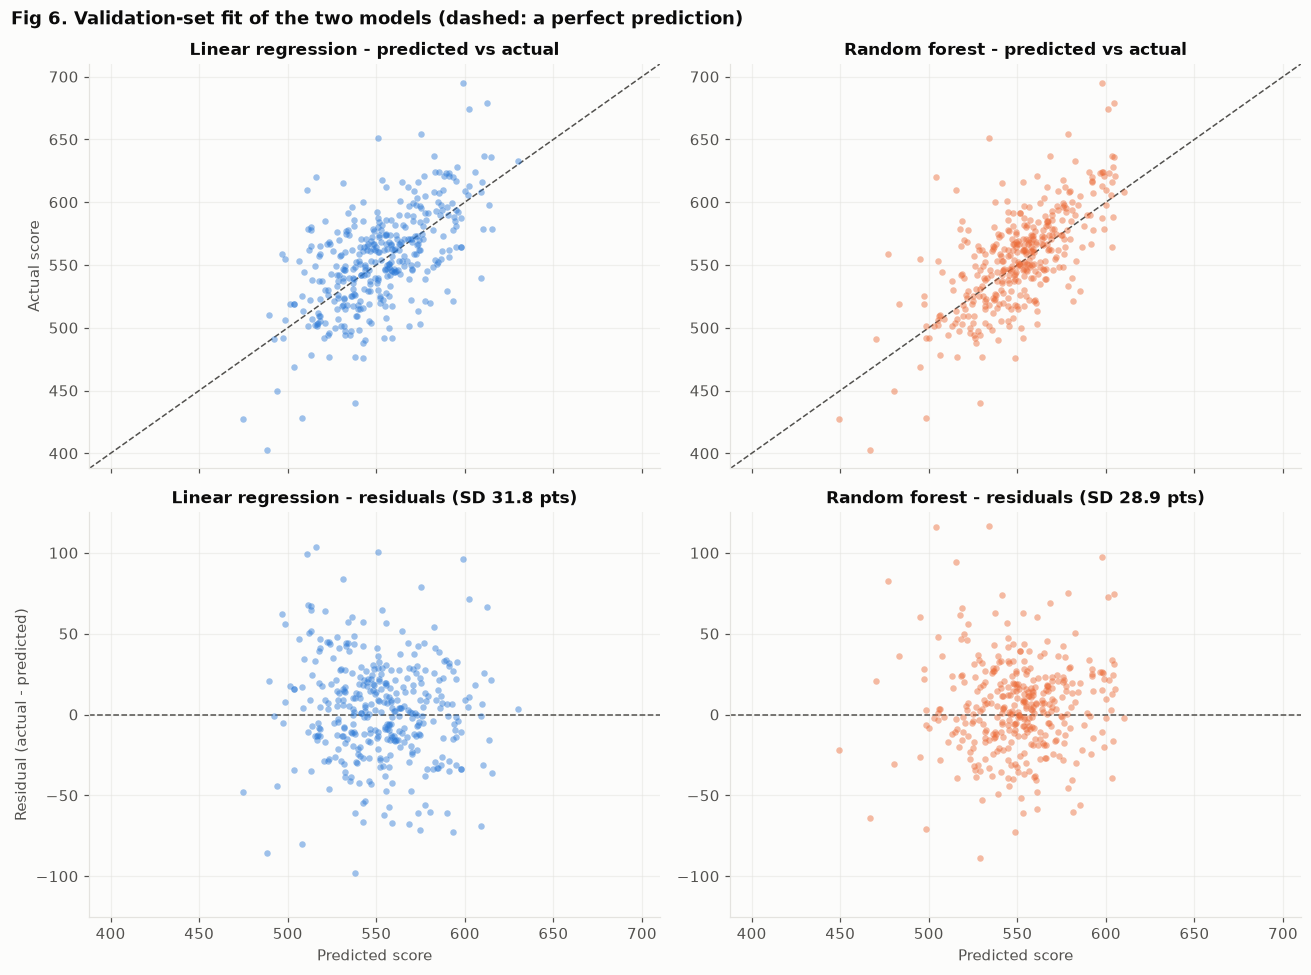

Actual scores span 403-695 points; forest predictions span 449-610


In [308]:
# Categorical slot 2 of the same palette, for the second model
ORANGE = "#eb6834"
MODEL_COLOURS = {"Linear regression": BLUE, "Random forest": ORANGE}

fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex="col")
score_limits = (min(y_val.min(), *(p.min() for p in val_predictions.values())) - 15,
                max(y_val.max(), *(p.max() for p in val_predictions.values())) + 15)
residual_limits = (-125, 125)

for column, (name, prediction) in enumerate(val_predictions.items()):
    colour = MODEL_COLOURS[name]
    residual = y_val - prediction

    ax = axes[0, column]
    ax.plot(score_limits, score_limits, color=INK_MUTED, linestyle="--", linewidth=1, zorder=1)
    ax.scatter(prediction, y_val, s=18, color=colour, alpha=0.45, linewidths=0, zorder=2)
    ax.set(xlim=score_limits, ylim=score_limits, title=f"{name} - predicted vs actual",
           ylabel="Actual score" if column == 0 else "")

    ax = axes[1, column]
    ax.axhline(0, color=INK_MUTED, linestyle="--", linewidth=1, zorder=1)
    ax.scatter(prediction, residual, s=18, color=colour, alpha=0.45, linewidths=0, zorder=2)
    ax.set(xlim=score_limits, ylim=residual_limits, xlabel="Predicted score",
           title=f"{name} - residuals (SD {residual.std():.1f} pts)",
           ylabel="Residual (actual - predicted)" if column == 0 else "")

fig.suptitle("Fig 6. Validation-set fit of the two models (dashed: a perfect prediction)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

print(f"Actual scores span {y_val.min():.0f}-{y_val.max():.0f} points; "
      f"forest predictions span {val_predictions['Random forest'].min():.0f}-"
      f"{val_predictions['Random forest'].max():.0f}")

**Fig 6.** Both clouds sit around the diagonal with no bend or funnel: the spread is about the same at a
predicted 500 as at 600, so neither model is systematically wrong at one end. The forest's cloud is tighter
(residual SD 28.9 vs 31.8 points).

The flaw in both is **compression**: actual scores run 403–695, but the forest only ever predicts 449–610. This
is ordinary regression towards the mean — at R² ≈ 0.46 a model keeps its average error down by not committing
to extremes. It matters for the next step: the biggest residuals will tend to belong to authorities with
genuinely extreme scores, so the over/under-performer list means "further from prediction than most", not a
ranking of merit.

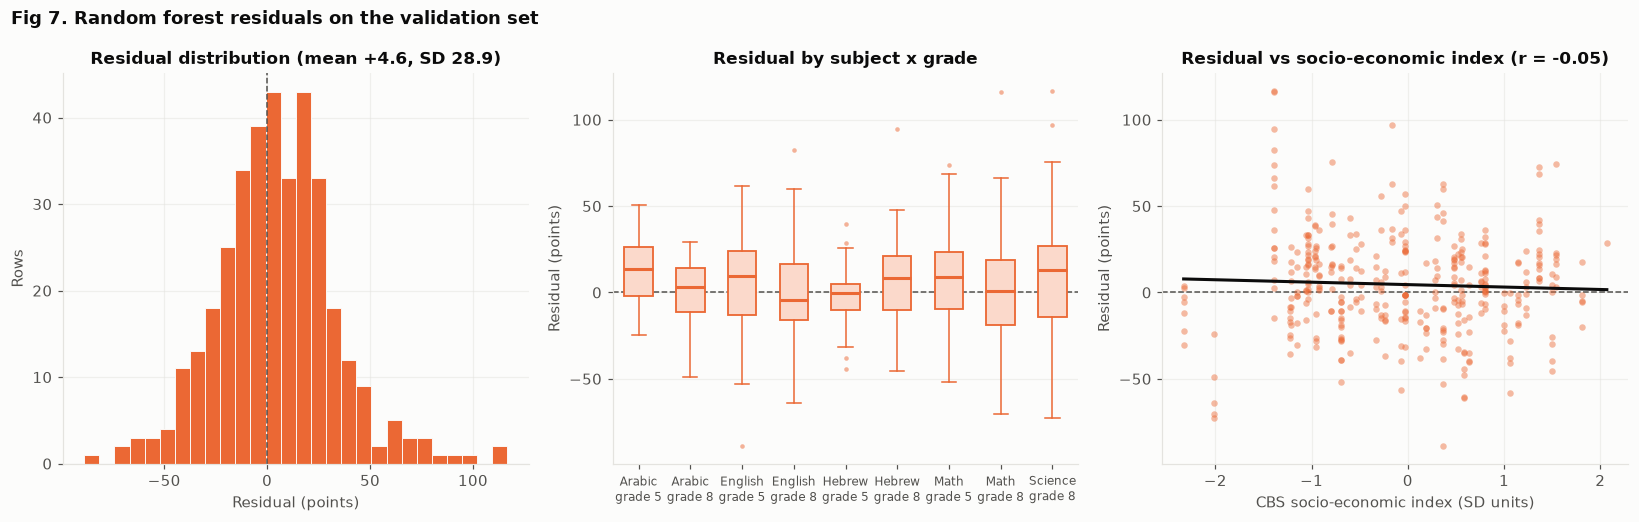

rows  mean    SD
subject_id shichva                  
Arabic     5          22  11.1  20.1
           8          22   1.0  18.1
English    5          40   4.2  30.8
           8          56   0.4  25.7
Hebrew     5          36  -1.8  17.3
           8          35   8.2  27.7
Math       5          40   8.3  26.6
           8          56   2.0  34.3
Science    8          55  10.0  37.9

In [309]:
chosen_name = "Random forest"
chosen_model = rf_search["unweighted"].best_estimator_
val_residual = pd.Series(y_val.to_numpy() - val_predictions[chosen_name], index=val_set.index)

# Same colour as the forest in Fig 6: these are its residuals
RESIDUAL_BOX = dict(BOX_STYLE)
RESIDUAL_BOX.update(
    boxprops=dict(facecolor="#fbd9cb", edgecolor=ORANGE, linewidth=1.2),
    medianprops=dict(color=ORANGE, linewidth=2),
    whiskerprops=dict(color=ORANGE), capprops=dict(color=ORANGE),
    flierprops=dict(marker="o", markersize=3, markerfacecolor=ORANGE, markeredgecolor="none", alpha=0.5),
)

fig, (ax_hist, ax_group, ax_ses) = plt.subplots(1, 3, figsize=(15, 4.8))

ax_hist.hist(val_residual, bins=28, color=ORANGE, edgecolor=SURFACE, linewidth=0.6)
ax_hist.axvline(0, color=INK_MUTED, linestyle="--", linewidth=1)
ax_hist.set(title=f"Residual distribution (mean {val_residual.mean():+.1f}, SD {val_residual.std():.1f})",
            xlabel="Residual (points)", ylabel="Rows")

val_groups = [key for key in GROUPS if ((val_set["subject_id"] == key[0]) & (val_set["shichva"] == key[1])).any()]
ax_group.axhline(0, color=INK_MUTED, linestyle="--", linewidth=1, zorder=1)
ax_group.boxplot([val_residual[(val_set["subject_id"] == s) & (val_set["shichva"] == g)] for s, g in val_groups],
                 tick_labels=[f"{SUBJECT_NAMES[s]}\ngrade {g}" for s, g in val_groups],
                 widths=0.55, zorder=2, **RESIDUAL_BOX)
ax_group.set(title="Residual by subject x grade", ylabel="Residual (points)")
ax_group.tick_params(axis="x", labelsize=8)
ax_group.grid(axis="x", visible=False)

ses = val_set["ses_index"]
ax_ses.axhline(0, color=INK_MUTED, linestyle="--", linewidth=1, zorder=1)
ax_ses.scatter(ses, val_residual, s=18, color=ORANGE, alpha=0.45, linewidths=0, zorder=2)
slope, intercept = np.polyfit(ses, val_residual, 1)
ses_grid = np.linspace(ses.min(), ses.max(), 50)
ax_ses.plot(ses_grid, intercept + slope * ses_grid, color=INK, linewidth=2, zorder=3)
ax_ses.set(title=f"Residual vs socio-economic index (r = {ses.corr(val_residual):.2f})",
           xlabel="CBS socio-economic index (SD units)", ylabel="Residual (points)")

fig.suptitle(f"Fig 7. {chosen_name} residuals on the validation set", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

display(val_residual.groupby([val_set["subject_id"].map(SUBJECT_NAMES), val_set["shichva"]])
        .agg(rows="count", mean="mean", SD="std").round(1))

**Fig 7.** Three checks on the forest's residuals.

- **Shape.** Symmetric and bell-shaped around zero, with no second hump, so there is no hidden group the model
  treats differently. The mean is +4.6 rather than 0 — the compression of Fig 6 showing up as a small bias. It
  is small next to the 28.9-point SD.
- **By subject × grade.** Every box straddles zero, so no test is systematically mispredicted. But the spreads
  differ a lot: an SD of 17 points in Hebrew grade 5 against 38 in Science grade 8. So the gaps have to be
  standardized within subject × grade before authorities are compared — a +30 residual in Hebrew grade 5 is a
  much rarer event than the same residual in Science grade 8.
- **Against the index.** Flat (r = −0.05). This is the important one. The model has already absorbed the
  socio-economic gradient, so what is left over is not explained by how rich or poor an authority is. The
  residuals therefore measure performance *relative to* socio-economic standing, which is exactly what the
  research question asks. Had this sloped, the gaps would still contain the gradient we want to hold constant.

### The test set, used once

Everything above was decided on the training and validation sets. The test set — 74 authorities, 547 rows, none
of them seen in training — is opened now for the model chosen on validation: the unweighted forest. The two
baselines are scored alongside it for reference. The weighted variants were rejected on validation and are not
re-run here; that is the point of holding the set back.

The forest is **not** refitted on train + validation first. That would score better, but then the model being
tested would not be the model that was selected.

In [310]:
test_results = []
for name, prediction in [
    ("Baseline: overall mean", predict_overall_mean(X_test)),
    ("Baseline: subject x grade mean", predict_group_mean(X_test)),
    (f"{chosen_name} (chosen on validation)", chosen_model.predict(X_test)),
]:
    test_results.append({
        "model": name,
        "R2": r2_score(y_test, prediction),
        "RMSE": mean_squared_error(y_test, prediction) ** 0.5,
        "MAE": mean_absolute_error(y_test, prediction),
        "R2 weighted": r2_score(y_test, prediction, sample_weight=w_test),
    })

test_prediction = chosen_model.predict(X_test)
test_residual = pd.Series(y_test.to_numpy() - test_prediction, index=test_set.index)

print(f"Test set: {len(test_set)} rows, {test_set['rashut'].nunique()} authorities, "
      f"{test_set['rashut'].isin(train_set['rashut']).sum()} of them seen in training")
print(f"Test residuals: mean {test_residual.mean():+.1f}, SD {test_residual.std():.1f}, "
      f"correlation with ses_index {test_set['ses_index'].corr(test_residual):.2f}")
pd.DataFrame(test_results).set_index("model").round(3)

Test set: 547 rows, 74 authorities, 0 of them seen in training
Test residuals: mean -3.3, SD 25.2, correlation with ses_index 0.07


,R2,RMSE,MAE,R2 weighted
model,,,,
Baseline: overall mean,-0.012,37.187,28.331,-0.007
Baseline: subject x grade mean,0.281,31.343,24.312,0.274
Random forest (chosen on validation),0.530,25.343,19.378,0.574


**Table 6. Test results.** On authorities it has never seen, the forest reaches **R² = 0.530, RMSE 25.3,
MAE 19.4**, against 0.281 for the subject × grade baseline. The residuals behave as they did on validation
(mean −3.3, SD 25.2, correlation with `ses_index` 0.07 — still flat).

The test score is slightly *better* than the validation score (0.530 vs 0.463). With only 48 validation and 74
test authorities, that is which authorities happened to land where, not a real improvement. The two agree:
**about half the variation in an authority's score is predictable** from its socio-economic characteristics
plus which test it is. The other half is not.

That other half is the rest of the project. An average miss of about 20 points, on tests spanning roughly
400–700, is the resolution at which we can call an authority an over- or under-performer.

One qualification: a row the model misses is an *average* it misses. Nothing here describes an individual
student, and the gaps must not be read that way.

## Over- and under-performing authorities

This is the main question. An authority whose scores sit consistently above its prediction is doing
better than its socio-economic profile would suggest, and the point is to find those authorities and see what
they have in common.

Three things have to be right before any authority can be named.

**The gap has to be out-of-fold.** Up to now the forest was fitted on 121 training authorities and scored on
the 48 validation and 74 test ones. Its residuals for a training authority are smaller than they should be,
because it was fitted to that authority. Ranking all 243 together on those residuals would flatter the
training half. So we predict every row with `cross_val_predict` and `GroupKFold` on `rashut`: the table is
split into 5 folds of whole authorities, and each authority is predicted by a forest fitted on the other four
folds. No authority is ever predicted by a model that has seen it.

**The gaps have to be comparable.** A residual of 30 points is a much rarer event in Hebrew grade 5 than in
Science grade 8, because the spread differs by test (Fig 7). So each row's gap is standardized within its own
subject and grade: divided by the spread of the gaps in that test. A gap of +1 means "one standard deviation
better than predicted, for this test".

**One number per authority, with its uncertainty.** We average the standardized gaps of each authority's rows
and keep three things: the mean, its standard error, and the share of the authority's rows that point the same
way as the mean.

In [311]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

X_all, y_all = data[FEATURES], data[TARGET]
oof_prediction = cross_val_predict(clone(chosen_model), X_all, y_all,
                                   cv=GroupKFold(n_splits=5), groups=data["rashut"])
oof_residual = pd.Series(y_all.to_numpy() - oof_prediction, index=data.index)

# Standardize within subject x grade, so a gap means the same thing in every test
by_test = oof_residual.groupby([data["subject_id"], data["shichva"]])
gap = (oof_residual - by_test.transform("mean")) / by_test.transform("std")

by_authority = gap.groupby(data["rashut"])
per_authority = pd.DataFrame({
    "rows": by_authority.size(),
    "gap": by_authority.mean(),
    "sd": by_authority.std(),
    "same_sign": by_authority.apply(lambda rows: float((np.sign(rows) == np.sign(rows.mean())).mean())),
    "ses_index": data.groupby("rashut")["ses_index"].first(),
    "ses_cluster": data.groupby("rashut")["ses_cluster"].first(),
}).join(authority_names[["name_en"]])
per_authority["se"] = per_authority["sd"] / np.sqrt(per_authority["rows"])
per_authority["t"] = per_authority["gap"] / per_authority["se"]

oof_r2 = r2_score(y_all, oof_prediction)
print(f"Out-of-fold R2 across all {data['rashut'].nunique()} authorities: {oof_r2:.3f} "
      f"(single split gave 0.463 on validation, 0.530 on test)")
print(f"Gap vs socio-economic index: r = {per_authority['gap'].corr(per_authority['ses_index']):.3f}")
print("\nSpread of the raw gaps, per test (points):")
display(oof_residual.groupby([data["subject_id"], data["shichva"]]).std().round(1)
        .rename(index=SUBJECT_NAMES, level=0).to_frame("SD"))

Out-of-fold R2 across all 243 authorities: 0.537 (single split gave 0.463 on validation, 0.530 on test)
Gap vs socio-economic index: r = 0.011

Spread of the raw gaps, per test (points):


SD
subject_id shichva      
Arabic     5        22.0
           8        24.4
English    5        28.0
           8        22.4
Hebrew     5        18.5
           8        21.1
Math       5        25.4
           8        30.2
Science    8        34.0

**The gaps are clean.** Out-of-fold R² is 0.537 over all 243 authorities, in line with the 0.463 and 0.530
from the single split, so nothing breaks when every authority is predicted out-of-fold.

The spread of the raw gaps runs from 18.5 points in Hebrew grade 5 to 34.0 in Science grade 8, which is why
they are standardized before averaging.

Most importantly, the gaps carry no socio-economic signal left: the correlation between an authority's mean gap
and its socio-economic index is **r = 0.011**. The model has already absorbed the gradient, so what remains
measures performance *relative to* socio-economic standing. That is exactly the quantity the research question
asks about.

In [312]:
# A single row cannot be checked for consistency, so those authorities are named and set aside
single_row = per_authority[per_authority["rows"] == 1]
eligible = per_authority[per_authority["rows"] >= 2]
print(f"Eligible: {len(eligible)} authorities. Set aside with one row only: {len(single_row)}")
display(single_row[["name_en", "gap", "ses_cluster"]].round(2))

# How many authorities get flagged under different rules
rule_counts = pd.DataFrame({
    f"|t| >= {t}": {
        f"rows agreeing >= {int(s * 100)}%":
            int(((eligible["t"].abs() >= t) & (eligible["same_sign"] >= s)).sum())
        for s in (0.6, 0.75, 1.0)
    }
    for t in (1.5, 2.0, 2.5)
})
display(rule_counts)

Eligible: 238 authorities. Set aside with one row only: 5


,name_en,gap,ses_cluster
rashut,,,
463,YAVNE'EL,0.74,3
1719,PARDESIYYA,-1.23,9
2675,KEFAR SHEMARYAHU,1.94,10
7400000,MEGILLOT DEAD SEA,-0.19,7
7500000,ARVOT HAYARDEN,-0.67,6


,|t| >= 1.5,|t| >= 2.0,|t| >= 2.5
rows agreeing >= 60%,131,112,96
rows agreeing >= 75%,111,99,89
rows agreeing >= 100%,65,64,64


**Choosing the rule.** Reading down the right-hand column: once we require *every* one of an authority's
rows to point the same way, the count is 65, 64, 64 as the `t` threshold moves from 1.5 to 2.5. The threshold
stops mattering, because an authority whose rows all agree already has a large `t`. The looser sign rules are
sensitive to it, which makes them arbitrary.

So the rule is: **an authority is an over- or under-performer if every one of its rows falls on the same side
of its prediction, and its mean gap is at least twice its standard error.** That gives 64 authorities, 33 over
and 31 under, out of 238 eligible. The remaining 174 are not "average" but simply not consistent enough to
call either way, which is the honest answer for most of them.

In [313]:
T_CUT, SIGN_CUT = 2.0, 1.0
is_flagged = (eligible["t"].abs() >= T_CUT) & (eligible["same_sign"] >= SIGN_CUT)
flagged = eligible[is_flagged].copy()
flagged["group"] = np.where(flagged["gap"] > 0, "over-performer", "under-performer")

print(f"Flagged: {len(flagged)} of {len(eligible)} eligible authorities "
      f"({(flagged['group'] == 'over-performer').sum()} over, "
      f"{(flagged['group'] == 'under-performer').sum()} under)")
print(f"Typical gap among the flagged: {flagged['gap'].abs().median():.2f} SD of its test, "
      f"which is about {flagged['gap'].abs().median() * oof_residual.std():.0f} score points")

SHOW = ["name_en", "rows", "gap", "se", "t", "ses_cluster"]
print("\nThe 10 clearest over-performers:")
display(flagged.nlargest(10, "gap")[SHOW].round(2))
print("The 10 clearest under-performers:")
display(flagged.nsmallest(10, "gap")[SHOW].round(2))

Flagged: 64 of 238 eligible authorities (33 over, 31 under)
Typical gap among the flagged: 0.98 SD of its test, which is about 26 score points

The 10 clearest over-performers:


,name_en,rows,gap,se,t,ses_cluster
rashut,,,,,,
5074,KAFAR YASIF,5,2.12,0.41,5.19,4
4500000,ALLONA,3,2.01,0.37,5.36,8
5371,FUREIDIS,5,1.84,0.36,5.13,3
4000000,EMEQ LOD,5,1.71,0.40,4.31,6
5116,ILUT,4,1.69,0.27,6.32,2
1222,RAMAT YISHAY,7,1.61,0.30,5.32,9
7800000,HAR HEVRON,7,1.43,0.34,4.22,5
6817,GIV'AT SHEMU'EL,7,1.40,0.20,6.90,8
5223,NAHEF,5,1.27,0.11,11.59,2


The 10 clearest under-performers:


,name_en,rows,gap,se,t,ses_cluster
rashut,,,,,,
5400000,HAARAVA HATIKHONA,7,-2.69,0.90,-2.98,7
10603,LAQYE,5,-2.08,0.17,-11.90,1
5413,JISR AZ-ZARQA,7,-1.88,0.18,-10.76,2
9449,BASMAT TAB'UN,5,-1.83,0.45,-4.04,3
80002,ZEFAT,7,-1.71,0.26,-6.72,2
100000,HAGALIL HAELYON,7,-1.69,0.18,-9.62,7
9985,BIR EL-MAKSUR,7,-1.42,0.38,-3.77,2
3800000,ESHKOL,7,-1.37,0.33,-4.12,6
85001,RAMLA,18,-1.23,0.17,-7.04,4


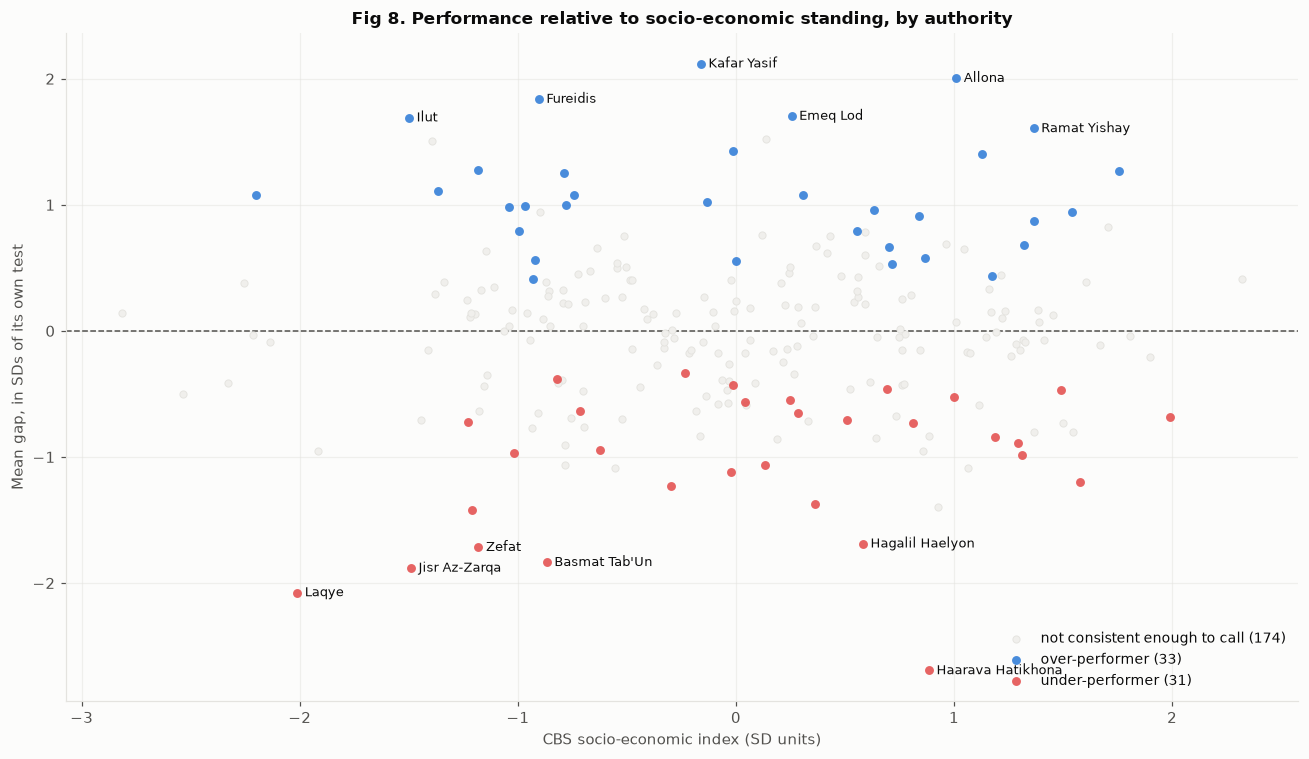

In [314]:
fig, ax = plt.subplots(figsize=(12, 7))

ax.axhline(0, color=INK_MUTED, linestyle="--", linewidth=1, zorder=1)
rest = eligible[~is_flagged]
ax.scatter(rest["ses_index"], rest["gap"], s=22, color=NEUTRAL, edgecolor=GRID,
           linewidths=0.6, zorder=2, label=f"not consistent enough to call ({len(rest)})")
for group, colour in [("over-performer", BLUE), ("under-performer", RED)]:
    part = flagged[flagged["group"] == group]
    ax.scatter(part["ses_index"], part["gap"], s=34, color=colour, alpha=0.85, linewidths=0,
               zorder=3, label=f"{group} ({len(part)})")

# Label the six clearest on each side
for _, r in pd.concat([flagged.nlargest(6, "gap"), flagged.nsmallest(6, "gap")]).iterrows():
    ax.annotate(r["name_en"].title(), (r["ses_index"], r["gap"]), xytext=(5, 0),
                textcoords="offset points", fontsize=8.5, va="center", color=INK)

ax.set(xlabel="CBS socio-economic index (SD units)",
       ylabel="Mean gap, in SDs of its own test",
       title="Fig 8. Performance relative to socio-economic standing, by authority")
ax.legend(frameon=False, loc="lower right", fontsize=9)
fig.tight_layout()
plt.show()

**Fig 8.** The vertical axis is what the project set out to measure: how far an authority sits from the score
its socio-economic profile predicts. The cloud is flat, with no tilt left to right, which is the visual version
of r = 0.011. Over- and under-performers appear at every socio-economic level, from Laqye and Jisr az-Zarqa in
clusters 1 and 2 to Haarava Hatikhona and Hagalil Haelyon in cluster 7.

That flatness is the result worth stating plainly. **Knowing an authority's socio-economic cluster tells you
nothing about whether it beats or misses its own prediction.** The gradient and the deviation from it are
separate phenomena.

The clearest over-performers are Kafar Yasif, Allona, Fureidis, Emeq Lod and Ilut. The clearest
under-performers are Haarava Hatikhona, Laqye, Jisr az-Zarqa, Basmat Tab'un and Zefat. Both lists mix sectors,
clusters and authority types.


### What distinguishes the two groups?

The plan was to compare over- and under-performers and report what separates them. There is a problem with
doing that on the CBS variables, and it is worth stating before the result.

The gaps come from a model that already used all 16 of those variables as predictors. Whatever they could
explain about an authority's score has already been removed from the gap. Looking for a difference in the same
variables is close to circular, and finding none would be the expected outcome rather than a finding.

So we look at two sets: the 16 variables the model used, and 6 authority-level variables it never saw, built
from the test-administration columns that were deliberately kept out of the features (number of schools, school
size, cohort size, students tested, response rate). Authority type (city, local council, regional council) was
also never a feature.

We measure the relationship as the **correlation between an authority's gap and each variable**, across all 238
eligible authorities. That is the same measure used in Fig 4 and Fig 5, and it suits the question better than
comparing the two flagged groups: it uses every authority rather than only the 64, and it keeps the size of
each gap instead of reducing it to a label. The medians of the two flagged groups are shown alongside, as
context.

In [315]:
rows_by_authority = data.copy()
rows_by_authority["students_per_school"] = (rows_by_authority["n_students_tested"]
                                           / rows_by_authority["n_schools_tested"])
rows_by_authority["cohort_size"] = (rows_by_authority["n_students_tested"]
                                    / (rows_by_authority["p_response"] / 100))
unseen = rows_by_authority.groupby("rashut").agg(
    schools_tested=("n_schools_tested", "mean"), schools=("n_schools", "mean"),
    students_per_school=("students_per_school", "mean"), students_tested=("n_students_tested", "mean"),
    cohort_size=("cohort_size", "mean"), response_rate=("p_response", "mean"))

seen = data.drop_duplicates("rashut").set_index("rashut")[["ses_index", "population"] + CBS_VARIABLES]
comparison = seen.join(unseen)
over_ids = flagged.index[flagged["group"] == "over-performer"]
under_ids = flagged.index[flagged["group"] == "under-performer"]

summary = []
for variable in comparison.columns:
    pair = pd.concat([eligible["gap"], comparison[variable]], axis=1).dropna()
    summary.append({
        "variable": variable,
        "used by the model": variable in FEATURES,
        "r with the gap": pair["gap"].corr(pair[variable]),
        "over-performers (median)": comparison.loc[over_ids, variable].median(),
        "under-performers (median)": comparison.loc[under_ids, variable].median(),
    })

characterization = pd.DataFrame(summary).set_index("variable")
characterization = characterization.reindex(
    characterization["r with the gap"].abs().sort_values(ascending=False).index)
print(f"Table 7. Each variable against the authority gap, over {len(eligible)} eligible authorities. "
      f"Medians are for the {len(over_ids)} over- and {len(under_ids)} under-performers.")
display(characterization.round(3))

# Authority type was never a model feature either
municipal_status = data.drop_duplicates("rashut").set_index("rashut")["municipal_status"]
authority_kind = pd.Series(np.where(municipal_status == 0, "city",
                           np.where(municipal_status == 99, "local council", "regional council")),
                           index=municipal_status.index, name="authority type")
print("Mean gap by authority type:")
display(eligible["gap"].groupby(authority_kind.loc[eligible.index]).agg(["count", "mean", "std"]).round(3))

Table 7. Each variable against the authority gap, over 238 eligible authorities. Medians are for the 33 over- and 31 under-performers.


,used by the model,r with the gap,over-performers (median),under-performers (median)
variable,,,,
response_rate,False,0.162,89.684,88.143
population,True,0.092,14845.313,17452.651
avg_vehicle_licence_fee,True,0.080,1365.040,1357.712
students_per_school,False,0.049,90.878,77.267
median_age,True,-0.033,27.000,30.000
pct_women_no_work_income_25_54,True,0.032,14.431,13.642
pct_income_support_20plus,True,-0.030,4.441,5.495
avg_years_schooling_25_54,True,0.028,12.717,12.618
pct_above_twice_avg_wage,True,0.026,9.862,8.756


Mean gap by authority type:


,count,mean,std
authority type,,,
city,75,0.043,0.610
local council,112,0.007,0.771
regional council,51,-0.087,0.821


**This is a null result, and it is the honest headline.** The analysis can say *which* authorities beat or miss
their socio-economic prediction, consistently and robustly. It cannot say *what* makes them do so. Everything
measured here about an authority, 16 socio-economic and demographic variables plus 6 structural ones and its
type, fails to separate Kafar Yasif from Jisr az-Zarqa once socio-economic standing is accounted for.

That points somewhere specific for interpretation. Whatever drives these gaps is plausibly school-level and
organisational, things like teaching quality, school leadership, municipal education policy or specific
programmes, and none of that appears in either dataset. Section 8 returns to what it would take to test that.

In [316]:
# Does the list survive using the linear model's gaps instead of the forest's?
oof_linear = cross_val_predict(clone(linear_model), X_all, y_all,
                               cv=GroupKFold(n_splits=5), groups=data["rashut"])
linear_residual = pd.Series(y_all.to_numpy() - oof_linear, index=data.index)
by_test_linear = linear_residual.groupby([data["subject_id"], data["shichva"]])
linear_gap = ((linear_residual - by_test_linear.transform("mean"))
              / by_test_linear.transform("std")).groupby(data["rashut"]).mean()

agreement = pd.DataFrame({"forest": per_authority["gap"], "linear": linear_gap}).dropna()
print(f"Authority gaps, forest vs linear: Spearman {agreement['forest'].rank().corr(agreement['linear'].rank()):.3f}")
print(f"Sign agreement on the {len(flagged)} flagged authorities: "
      f"{100 * (np.sign(linear_gap.loc[flagged.index]) == np.sign(flagged['gap'])).mean():.0f}%")

# Bonus check: the 28 authorities tested in more than one year
years_per_authority = data.groupby("rashut")["year"].nunique()
multi_year = years_per_authority[years_per_authority >= 2].index
by_year = gap.groupby([data["rashut"], data["year"]]).mean().loc[multi_year]
year_agreement = by_year.groupby(level=0).apply(
    lambda years: float((np.sign(years) == np.sign(years.mean())).mean()))
print(f"\nAuthorities tested in more than one year: {len(multi_year)}")
print(f"Of those, share whose years all agree in sign: {(year_agreement == 1).mean():.0%}")
print(f"Flagged authorities that are multi-year: {len(set(multi_year) & set(flagged.index))}")

Authority gaps, forest vs linear: Spearman 0.849
Sign agreement on the 64 flagged authorities: 98%

Authorities tested in more than one year: 28
Of those, share whose years all agree in sign: 82%
Flagged authorities that are multi-year: 5


**The list holds up.** Swapping the forest for the linear model, which is a different model family with a
different fit (out-of-fold R² 0.400 against 0.537), moves the authority rankings very little: Spearman 0.849,
and **98% of the 64 flagged authorities keep the same sign**. The over- and under-performers are a property of
the data, not of one model's quirks.

The year check points the same way. Of the 28 authorities tested in more than one year, 82% have every year
falling on the same side of their prediction, and 5 of the 64 flagged authorities are in that group. Year-to-
year consistency can only be checked for those 28, because the Meitzav rotates schools through three national
groups tested once every three years, so the other 215 authorities appear in a single year.

In [317]:
# Full ranked table for the appendix, and the figures the report refers back to
ranked = (per_authority.sort_values("gap", ascending=False)
          [["name_en", "rows", "gap", "se", "t", "same_sign", "ses_index", "ses_cluster"]]
          .round(3))
ranked.to_excel(Path("data") / "authority_gaps.xlsx")
print(f"Ranked gaps for all {len(ranked)} authorities written to data/authority_gaps.xlsx")
display(ranked.head(5))

Ranked gaps for all 243 authorities written to data/authority_gaps.xlsx


,name_en,rows,gap,se,t,same_sign,ses_index,ses_cluster
rashut,,,,,,,,
5074,KAFAR YASIF,5,2.121,0.409,5.188,1.0,-0.161,4
4500000,ALLONA,3,2.006,0.374,5.359,1.0,1.010,8
2675,KEFAR SHEMARYAHU,1,1.936,NaN,NaN,1.0,2.068,10
5371,FUREIDIS,5,1.840,0.359,5.127,1.0,-0.904,3
4000000,EMEQ LOD,5,1.705,0.396,4.311,1.0,0.255,6


## Grouping authorities by achievement

The instructor called this the most interesting part of the proposal: build groups of authorities from the data
itself and see whether they line up with the official socio-economic clusters. It matters more after Table 7.
Nothing we measured explains the gaps, so this is the remaining place structure could show up.

**Which subjects go into the profile.** Not all nine subject and grade combinations, because the matrix is only
69.5% full and the holes are not random. Only 10 of the 243 authorities are tested in all nine, and all 10 are
mixed cities. Worse, Arabic is tested in 100% of Arabic-language authorities and 0% of Hebrew-language ones,
and Hebrew is the mirror image, so including either subject would make the distances encode the sector and
K-Means would simply rediscover the Hebrew/Arabic split we already have in `norm_id`.

So we use the three grade 8 subjects taught in both sectors: **English, Mathematics and Science**. 223 of the
243 authorities have all three, across all three sectors. Each column is standardized first, since the levels
differ (about 517, 535 and 574), and otherwise distance would mostly record which of the three an authority
happens to sit high on.

**Two different inputs, two different questions.**

- **Scores.** The plan's original clustering. Groups authorities by how well they do. Expect it to partly track
  socio-economic level, because that is what drives scores.
- **The Step 8 gaps.** Groups authorities by how far they are from their *prediction*. These are already net of
  socio-economic standing (r = 0.011), so this asks whether authorities deviate in recognisable *patterns*
  rather than uniformly.

In [318]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score
from sklearn.preprocessing import StandardScaler

CORE = [(2, 8), (4, 8), (5, 8)]                      # English, Math, Science - grade 8, both sectors
CORE_LABELS = {(2, 8): "English gr 8", (4, 8): "Math gr 8", (5, 8): "Science gr 8"}

def build_profile(values, name):
    # Average over years first: 28 authorities are tested in more than one year
    wide = (pd.DataFrame({"rashut": data["rashut"], "subject_id": data["subject_id"],
                          "shichva": data["shichva"], name: values})
            .pivot_table(index="rashut", columns=["subject_id", "shichva"], values=name, aggfunc="mean"))
    return wide[CORE].rename(columns=CORE_LABELS).dropna()

score_profile = build_profile(data["score"].to_numpy(), "score")
gap_profile = build_profile(gap.to_numpy(), "gap")
official_cluster = data.groupby("rashut")["ses_cluster"].first()

print(f"Authorities with all three grade 8 subjects: {len(score_profile)} of {data['rashut'].nunique()}")
print("Mean score per column (why they are standardized first):")
display(score_profile.mean().round(1).to_frame("mean score"))

Authorities with all three grade 8 subjects: 223 of 243
Mean score per column (why they are standardized first):


,,mean score
subject_id,shichva,
2,8,516.8
4,8,535.1
5,8,573.9


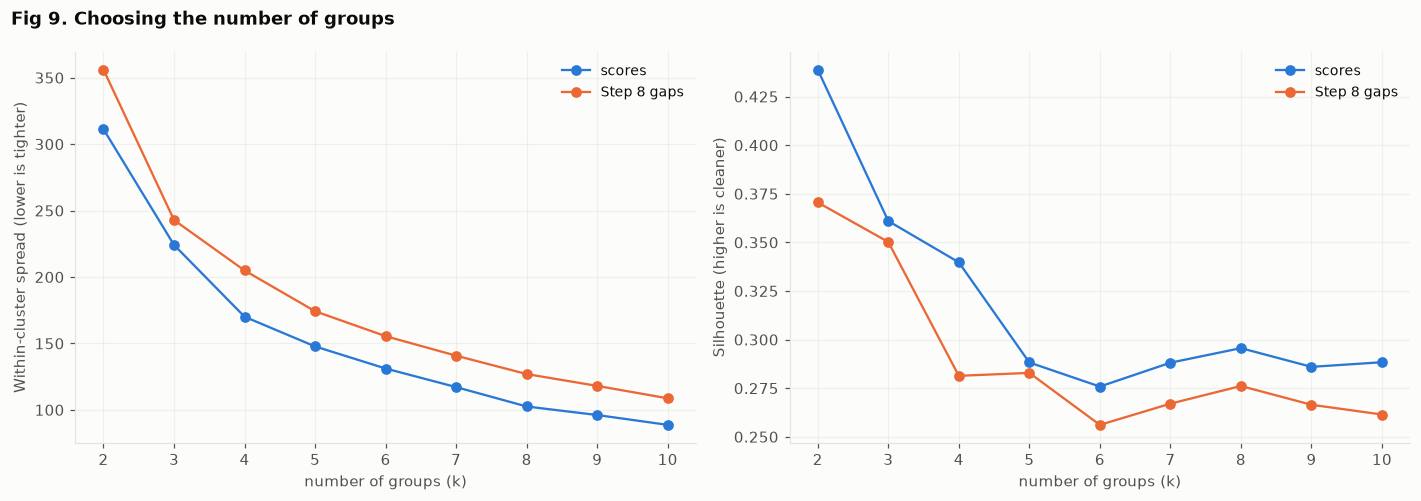

scores                gaps           
    inertia silhouette  inertia silhouette
k                                         
2   311.194      0.439  356.031      0.371
3   224.118      0.361  242.866      0.350
4   170.087      0.340  204.901      0.281
5   147.751      0.288  174.218      0.283
6   131.122      0.276  155.470      0.256
7   117.143      0.288  140.775      0.267
8   102.536      0.296  126.948      0.276
9    96.121      0.286  118.039      0.266
10   88.704      0.288  108.698      0.261

In [319]:
def sweep(frame):
    X = StandardScaler().fit_transform(frame)
    rows = []
    for k in range(2, 11):
        model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X)
        rows.append({"k": k, "inertia": model.inertia_, "silhouette": silhouette_score(X, model.labels_)})
    return X, pd.DataFrame(rows).set_index("k")

X_score, sweep_score = sweep(score_profile)
X_gap, sweep_gap = sweep(gap_profile)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, column, label in zip(axes, ["inertia", "silhouette"],
                             ["Within-cluster spread (lower is tighter)", "Silhouette (higher is cleaner)"]):
    ax.plot(sweep_score.index, sweep_score[column], marker="o", color=BLUE, label="scores")
    ax.plot(sweep_gap.index, sweep_gap[column], marker="o", color=ORANGE, label="Step 8 gaps")
    ax.set(xlabel="number of groups (k)", ylabel=label, xticks=range(2, 11))
    ax.legend(frameon=False, fontsize=9)
fig.suptitle("Fig 9. Choosing the number of groups", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

display(pd.concat({"scores": sweep_score, "gaps": sweep_gap}, axis=1).round(3))

**Fig 9.** The within-cluster spread falls smoothly with no obvious elbow in either input, which is what
usually happens with continuous data that has no natural grouping. The silhouette is highest at **k = 2** for
both (0.44 for scores, 0.37 for gaps) and drops after that, so if we were choosing purely on these measures we
would take two groups.

Two groups is too coarse for the comparison we actually want, so we report both: **k = 2**, which the measures
prefer, and **k = 10**, which lines up one-to-one against the official 1 to 10 clusters. Reporting both is the
honest version, since the official clustering has 10 groups whether or not the achievement data wants 10.

In [320]:
def cluster_and_compare(frame, X, label):
    results, assignments = [], {}
    for k in (2, 10):
        model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X)
        labels = pd.Series(model.labels_, index=frame.index)
        # Number our groups from weakest to strongest so the comparison reads in the same direction
        order = frame.mean(axis=1).groupby(labels).mean().sort_values().index
        ranked = labels.map({cluster: i + 1 for i, cluster in enumerate(order)})
        official = official_cluster.loc[frame.index]
        results.append({
            "input": label, "k": k,
            "Adjusted Rand Index": adjusted_rand_score(official, ranked),
            "Normalized mutual information": normalized_mutual_info_score(official, ranked),
            "Spearman (our rank vs official)": official.rank().corr(ranked.rank()),
        })
        assignments[k] = ranked
    return results, assignments

score_results, score_groups = cluster_and_compare(score_profile, X_score, "achievement scores")
gap_results, gap_groups = cluster_and_compare(gap_profile, X_gap, "Step 8 gaps")

agreement = pd.DataFrame(score_results + gap_results).set_index(["input", "k"])
print("Table 8. Agreement between our groups and the official CBS clusters.")
print("ARI and mutual information ask whether the two partitions put the same authorities together")
print("(0 = no better than chance). Spearman asks the weaker question of whether they merely rank in the")
print("same order.")
display(agreement.round(3))

print("Group centres, k = 10 on scores (original units, weakest group first):")
display(score_profile.groupby(score_groups[10]).mean().round(1))

Table 8. Agreement between our groups and the official CBS clusters.
ARI and mutual information ask whether the two partitions put the same authorities together
(0 = no better than chance). Spearman asks the weaker question of whether they merely rank in the
same order.


Adjusted Rand Index  Normalized mutual information  \
input              k                                                        
achievement scores 2                 0.039                          0.119   
                   10                0.086                          0.258   
Step 8 gaps        2                -0.001                          0.010   
                   10               -0.001                          0.088   

                       Spearman (our rank vs official)  
input              k                                    
achievement scores 2                             0.473  
                   10                            0.618  
Step 8 gaps        2                             0.078  
                   10                            0.087

Group centres, k = 10 on scores (original units, weakest group first):


subject_id,2,4,5
shichva,8,8,8
1,438.6,455.8,508.4
2,465.4,487.2,548.0
3,500.6,503.1,524.6
4,489.8,525.7,566.6
5,523.2,519.1,562.6
6,515.9,550.8,598.7
7,545.5,555.1,579.4
8,540.1,568.7,636.7
9,568.2,589.7,610.3


**Table 8. The two systems agree on direction but not on grouping.**

Clustering the **scores**, the Adjusted Rand Index is 0.086 at k = 10 and the mutual information 0.258. Both
are low: knowing an authority's achievement group tells you little about which official cluster it is in. But
Spearman between the two orderings is **0.618**, and the group centres rise steadily from 439/456/508 points in
the weakest group to 562/616/677 in the strongest. So the achievement groups do line up with socio-economic
standing *in order*, while disagreeing about where the boundaries fall and which authority belongs where.

That combination is the interesting part. It is not that the official clusters are unrelated to achievement.
They predict the ranking reasonably well. It is that they are not interchangeable with it: a tenth of
authorities sit three or more clusters away from where their achievement would place them.

Clustering the **gaps** gives ARI of **-0.001** and Spearman of 0.078, which is as close to no relationship as
this kind of measure gets. That is the expected result and a useful check: the gaps were built to be
independent of socio-economic standing, and grouping them recovers nothing about the official clusters.

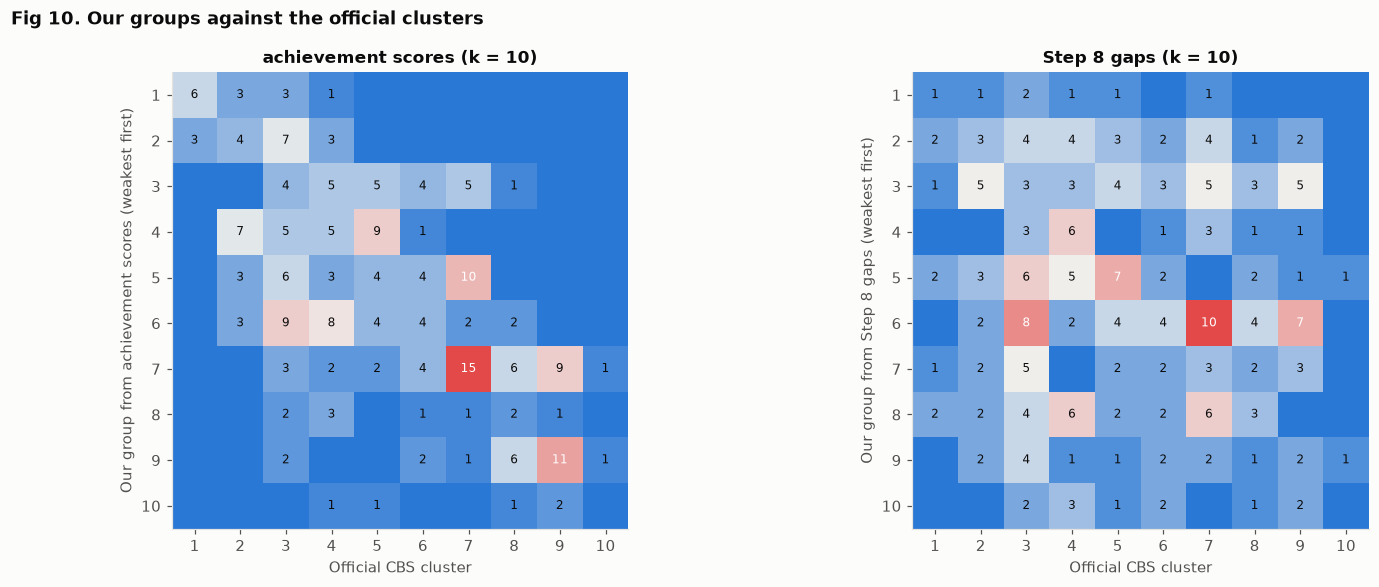

In [321]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))

for ax, (name, groups) in zip(axes, [("achievement scores", score_groups), ("Step 8 gaps", gap_groups)]):
    table = pd.crosstab(groups[10], official_cluster.loc[groups[10].index])
    table = table.reindex(index=range(1, 11), columns=range(1, 11), fill_value=0)
    image = ax.imshow(table, cmap=diverging.reversed(), vmin=0, vmax=table.values.max())
    ax.set(xticks=range(10), yticks=range(10),
           xticklabels=range(1, 11), yticklabels=range(1, 11),
           xlabel="Official CBS cluster", ylabel=f"Our group from {name} (weakest first)",
           title=f"{name} (k = 10)")
    ax.grid(False)
    for i in range(10):
        for j in range(10):
            count = table.iat[i, j]
            if count:
                ax.text(j, i, count, ha="center", va="center", fontsize=8,
                        color="white" if count > table.values.max() * 0.6 else INK)

fig.suptitle("Fig 10. Our groups against the official clusters", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

**Fig 10.** The left panel shows a loose diagonal: authorities in low official clusters tend to land in low
achievement groups, but the band is wide and there is weight well off the diagonal. The right panel, from the
gaps, has no diagonal at all. The counts are scattered evenly across the grid, which is what independence
looks like.

In [322]:
# Where do the two systems disagree, and are those the authorities Step 8 flagged?
achievement_rank = score_groups[10]
difference = (achievement_rank - official_cluster.loc[achievement_rank.index]).rename("difference")
flagged_label = flagged["group"].map({"over-performer": "over", "under-performer": "under"})

mismatch = pd.DataFrame({
    "our group": achievement_rank,
    "official cluster": official_cluster.loc[achievement_rank.index],
    "difference": difference,
}).join(authority_names[["name_en"]])
mismatch["Step 8"] = [flagged_label.get(a, "") for a in mismatch.index]

print(f"Authorities at least 3 clusters away from their achievement group: "
      f"{int(difference.abs().ge(3).sum())} of {len(difference)}. "
      f"Mean distance: {difference.abs().mean():.2f} clusters.")
SHOW = ["name_en", "our group", "official cluster", "difference", "Step 8"]
print("\nDoing better than their official cluster suggests:")
display(mismatch.nlargest(8, "difference")[SHOW])
print("Doing worse:")
display(mismatch.nsmallest(8, "difference")[SHOW])

overlap = pd.crosstab(achievement_rank.loc[flagged_label.index.intersection(achievement_rank.index)],
                      flagged_label).reindex(range(1, 11), fill_value=0)
overlap["share over"] = (overlap["over"] / overlap.sum(axis=1)).round(2)
print("Step 8's flagged authorities across our achievement groups:")
display(overlap)

Authorities at least 3 clusters away from their achievement group: 43 of 223. Mean distance: 1.54 clusters.

Doing better than their official cluster suggests:


,name_en,our group,official cluster,difference,Step 8
rashut,,,,,
5074,KAFAR YASIF,10,4,6,over
6338,KAFAR BARA,9,3,6,
42010,MAJDAL SHAMS,9,3,6,
4929,DEIR HANNA,8,3,5,over
5025,YIRKA,8,3,5,over
7800000,HAR HEVRON,10,5,5,over
5058,KAOKAB ABU AL-HIJA,8,4,4,
5173,MAZRA'A,8,4,4,


Doing worse:


,name_en,our group,official cluster,difference,Step 8
rashut,,,,,
3500000,YO'AV,3,8,-5,
100000,HAGALIL HAELYON,3,7,-4,under
2600000,MATTE YEHUDA,3,7,-4,
3300000,BE'ER TUVEYA,3,7,-4,
3600000,HOF ASHQELON,3,7,-4,
3700000,SHA'AR HANEGEV,3,7,-4,
6668,OMER,7,10,-3,
10348,QIRYAT MAL'AKHI,1,4,-3,


Step 8's flagged authorities across our achievement groups:


group,over,under,share over
row_0,,,
1,0,4,0.00
2,1,5,0.17
3,0,5,0.00
4,0,2,0.00
5,0,6,0.00
6,8,0,1.00
7,4,6,0.40
8,4,0,1.00
9,5,0,1.00


**The two methods point at the same authorities.** Of the eight authorities doing best relative to their
official cluster, four are Step 8 over-performers: Kafar Yasif (+6 clusters), Deir Hanna (+5), Yirka (+5) and
Har Hevron (+5). Kafar Bara and Majdal Shams are both +6 without clearing Step 8's consistency bar. On the
other side Hagalil Haelyon (-4) is a Step 8 under-performer.

**The under-performing end has a pattern the Table 7 correlations missed.** Six of the eight authorities
furthest below their official cluster are regional councils: Yo'av, Hagalil Haelyon, Matte Yehuda, Be'er
Tuveya, Hof Ashqelon and Sha'ar HaNegev. Table 7 found authority type almost unrelated to the gap on average
(mean gaps of +0.04, +0.01 and -0.09), and both statements are true: regional councils are not worse on
average, but they are over-represented at the extreme. A regional council is a collection of small separate
communities sharing an administration, so its single average score covers more internal variation than a
town's does, which is a plausible reason for extremes in both directions.

⚠️ **The overlap is not independent confirmation, and must not be reported as such.** Step 8's gaps correlate
0.75 with an authority's raw mean score, and the achievement groups are built from those same scores. Both
methods lean on the same underlying quantity, so agreement is partly built in. What the overlap does show is
that the finding survives being computed a second way, with a different algorithm and no model.

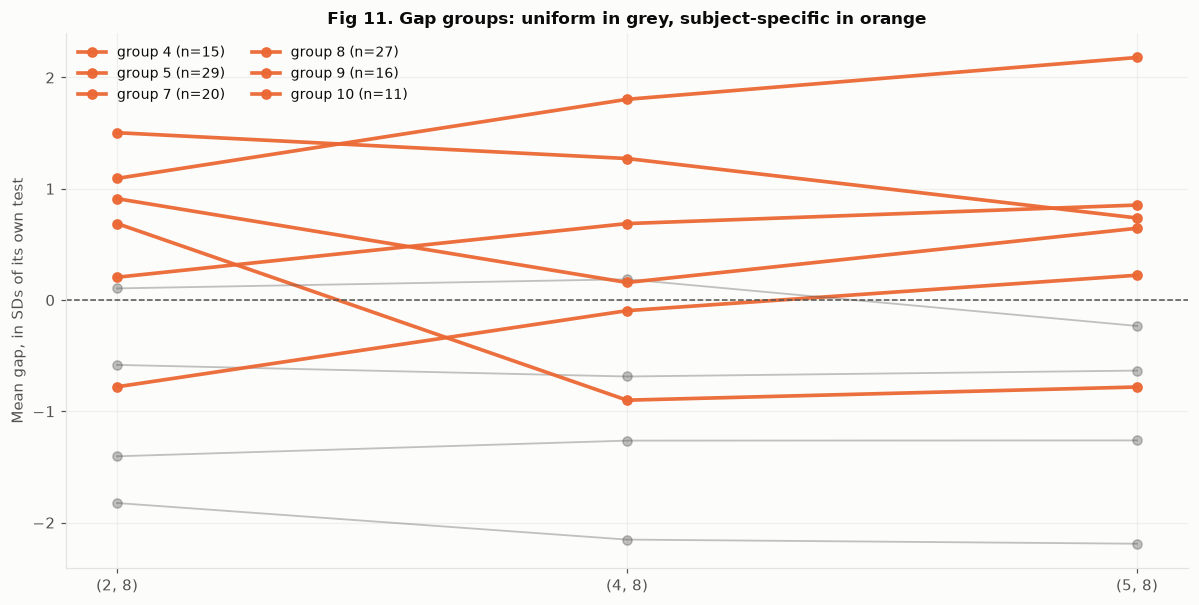

,level (mean of the three),spread across subjects,authorities
1,-2.06,0.37,7
2,-1.31,0.14,25
3,-0.63,0.10,32
4,-0.33,1.59,15
5,-0.22,1.00,29
6,0.02,0.42,41
7,0.57,0.75,20
8,0.58,0.65,27
9,1.17,0.77,16
10,1.69,1.09,11


In [323]:
# Do the gap groups differ in shape, or only in level?
gap_centres = gap_profile.groupby(gap_groups[10]).mean()
shape = pd.DataFrame({
    "level (mean of the three)": gap_centres.mean(axis=1),
    "spread across subjects": gap_centres.max(axis=1) - gap_centres.min(axis=1),
    "authorities": gap_groups[10].value_counts().sort_index(),
})

fig, ax = plt.subplots(figsize=(11, 5.6))
positions = np.arange(len(gap_centres.columns))
for group, centre in gap_centres.iterrows():
    uniform = shape.loc[group, "spread across subjects"] < 0.5
    ax.plot(positions, centre.to_numpy(), marker="o", linewidth=2.4 if not uniform else 1.2,
            alpha=0.95 if not uniform else 0.35,
            color=ORANGE if not uniform else INK_MUTED,
            label=f"group {group} (n={shape.loc[group, 'authorities']})" if not uniform else None)
ax.axhline(0, color=INK_MUTED, linestyle="--", linewidth=1)
ax.set(xticks=positions, xticklabels=[c for c in gap_centres.columns],
       ylabel="Mean gap, in SDs of its own test",
       title="Fig 11. Gap groups: uniform in grey, subject-specific in orange")
ax.legend(frameon=False, fontsize=9, ncol=2)
fig.tight_layout()
plt.show()

display(shape.round(2))

**Fig 11. Some authorities are subject-specific, not uniformly good or bad.** This is the one thing in this
section that Step 8 could not have told us, because Step 8 reduced each authority to a single number.

At k = 2 the two gap groups differ almost entirely in level: their spread across the three subjects is 0.05 and
0.06, meaning each group sits flat, above or below prediction by about the same amount in every subject. At
that resolution the clustering adds nothing beyond the single gap already reported.

At k = 10 four groups are genuinely tilted. Group 4 (15 authorities) is **above prediction in English and below
it in Mathematics and Science**, a spread of 1.59 SDs across subjects. Group 5 (29 authorities) is the reverse,
weak in English while average or better in the other two. Groups 9 and 10 combine a high overall level with a
tilt of about 1 SD.

So "over-performing" is not one thing. Some authorities beat their prediction across the board, and others do
so in one subject while falling behind in another, which points to subject-specific teaching capacity rather
than a general authority-wide effect. That distinction is worth more to a policy reader than the ranking
itself: an authority strong in English and weak in Mathematics needs something different from one that is
uniformly behind.

In [324]:
# Save the group assignments alongside the gaps for the appendix
clusters_out = pd.DataFrame({
    "achievement group (k=10)": score_groups[10],
    "achievement group (k=2)": score_groups[2],
    "gap group (k=10)": gap_groups[10],
    "official cluster": official_cluster.loc[score_profile.index],
}).join(authority_names[["name_en"]]).join(per_authority[["gap", "rows"]])
clusters_out.to_excel(Path("data") / "authority_clusters.xlsx")
print(f"Group assignments for {len(clusters_out)} authorities written to data/authority_clusters.xlsx")
display(clusters_out.head(5))

Group assignments for 223 authorities written to data/authority_clusters.xlsx


,achievement group (k=10),achievement group (k=2),gap group (k=10),official cluster,name_en,gap,rows
rashut,,,,,,,
281,7,2,3,9,MAZKERET BATYA,-0.202848,7
315,2,1,3,3,OFAQIM,-0.476577,5
703,6,2,8,4,ASHDOD,1.021366,19
992,3,1,4,3,MIZPE RAMON,0.231411,7
1222,10,2,10,9,RAMAT YISHAY,1.607238,7


## High or low: the same question as a classification

So far the score has been predicted as a number. Here we turn it into a two-way label and ask a classifier to
tell the two classes apart. The point is not to beat the regression but to check the finding from a second
angle, and to see whether anything shows up that a continuous model smoothed over.

**The rule, stated exactly:**

> A row is labelled **High** if its `score` is strictly above the median `score` of its own
> `(subject_id, shichva)` group, where that median is computed on the **training set only**. Otherwise it is
> labelled **Low**.

**Why within each subject and grade.** A single overall median would mostly record which test a row comes from.
Fig 1 showed the group medians running from 519 in English grade 8 to 604 in Arabic grade 5, against an overall
median of 551, so a pooled cut would label most Arabic grade 5 rows High and most English grade 8 rows Low
before socio-economic standing entered the picture at all. The classifier would then get good at identifying
the subject, which we already know from the `subject_id` column. The next cell shows this rather than asserting
it.

**Why the training set only.** If the medians came from the whole table, the label of a test row would depend on
test scores, and the leak would flatter every number that follows. Computing them on training rows and applying
them unchanged to validation and test keeps the label honest. One consequence: validation and test are then not
exactly half High, because the training median is not their median.

Everything else is reused from the regression: the same cluster-stratified split, the same 20 features, the same
`make_pipeline` helper, and `GroupKFold` for tuning. **No sample weighting** — it was tested in the regression
and made results worse (R² 0.463 to 0.413), so applying it here would contradict our own result.

Given the regression reached test R² 0.530, a classifier on the same information should land somewhere around
70 to 80% accuracy against a roughly 50% baseline. Much higher would be a sign the label is leaking something.

In [325]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score,
                             recall_score)

group_median = train_set.groupby(GROUP_KEYS)[TARGET].median()
overall_median = train_set[TARGET].median()

def label_high(rows):
    own_median = rows.join(group_median.rename("cut"), on=GROUP_KEYS)["cut"]
    return (rows[TARGET] > own_median).astype(int)

y_train, y_val, y_test = label_high(train_set), label_high(val_set), label_high(test_set)
X_train, X_val, X_test = train_set[FEATURES], val_set[FEATURES], test_set[FEATURES]

balance = pd.DataFrame({
    "rows": [len(y_train), len(y_val), len(y_test)],
    "share labelled High": [y_train.mean(), y_val.mean(), y_test.mean()],
}, index=["train", "validation", "test"])
print(f"Overall training median: {overall_median:.1f}. Medians per subject x grade:")
display(group_median.rename(index=SUBJECT_NAMES, level=0).round(1).to_frame("training median"))
display(balance.round(3))

# The demonstration: what a single pooled median would have labelled
comparison = pd.DataFrame({
    "if we used one overall median": (data[TARGET] > overall_median).astype(int)
        .groupby([data["subject_id"], data["shichva"]]).mean(),
    "within subject x grade (what we use)": label_high(data)
        .groupby([data["subject_id"], data["shichva"]]).mean(),
})
print("Share of rows that would be labelled High:")
display(comparison.rename(index=SUBJECT_NAMES, level=0).round(2))

Overall training median: 551.0. Medians per subject x grade:


training median
subject_id shichva                 
Arabic     5                  603.0
           8                  564.0
English    5                  540.0
           8                  518.0
Hebrew     5                  543.5
           8                  559.0
Math       5                  564.0
           8                  539.0
Science    8                  579.5

,rows,share labelled High
train,840,0.492
validation,362,0.575
test,547,0.433


Share of rows that would be labelled High:


if we used one overall median  \
subject_id shichva                                  
Arabic     5                                 0.87   
           8                                 0.62   
English    5                                 0.39   
           8                                 0.18   
Hebrew     5                                 0.28   
           8                                 0.58   
Math       5                                 0.66   
           8                                 0.39   
Science    8                                 0.75   

                    within subject x grade (what we use)  
subject_id shichva                                        
Arabic     5                                        0.50  
           8                                        0.47  
English    5                                        0.53  
           8                                        0.51  
Hebrew     5                                        0.51  
           8                                        0.48  
Math       5                                        0.47  
           8                                        0.50  
Science    8                                        0.46

**The pooled median would have encoded the test, not the authority.** Under a single cut at 551, **87%** of
Arabic grade 5 rows are High and only **18%** of English grade 8 rows are, with Science grade 8 at 75% and
Hebrew grade 5 at 28%. A classifier trained on that label would mostly be learning which exam a row came from.

Cut within each subject and grade, every group sits between 0.46 and 0.53. The label now means "did better than
other authorities on this same test", which is the thing socio-economic standing might explain.

The class balance also shows the training-only rule working as intended: training is 49.2% High by construction,
while validation comes out at 57.5% and test at 43.3%. Those sets simply contain authorities that sit above or
below the training medians, and that is the honest consequence of not letting them set their own cut. It does
mean the majority-class baseline scores differently on each set, which the next table has to be read against.

In [326]:
results = []

def record_classifier(name, y_true, prediction):
    results.append({
        "model": name,
        "accuracy": accuracy_score(y_true, prediction),
        "precision": precision_score(y_true, prediction, zero_division=0),
        "recall": recall_score(y_true, prediction, zero_division=0),
        "F1": f1_score(y_true, prediction, zero_division=0),
    })

# Baseline: always predict whichever class is larger in training
majority_class = int(y_train.mean() >= 0.5)
record_classifier("Baseline: majority class", y_val, np.full(len(y_val), majority_class))

logistic = make_pipeline(LogisticRegression(max_iter=2000, random_state=RANDOM_STATE), drop_first=True)
logistic.fit(X_train, y_train)
record_classifier("Logistic regression", y_val, logistic.predict(X_val))

CLASSIFIER_GRID = {"model__max_depth": [None, 8, 16], "model__min_samples_leaf": [1, 3, 10],
                   "model__max_features": ["sqrt", 0.3, 1.0]}
forest_search = GridSearchCV(
    make_pipeline(RandomForestClassifier(n_estimators=400, random_state=RANDOM_STATE, n_jobs=-1),
                  drop_first=False),
    CLASSIFIER_GRID, cv=TUNING_CV, scoring="accuracy")
forest_search.fit(X_train, y_train, groups=train_groups)
forest_classifier = forest_search.best_estimator_
record_classifier("Random forest", y_val, forest_classifier.predict(X_val))

print("Forest tuning:", {k.removeprefix("model__"): v for k, v in forest_search.best_params_.items()},
      f"| CV accuracy {forest_search.best_score_:.3f} "
      f"(worst in grid {forest_search.cv_results_['mean_test_score'].min():.3f})")
print("\nTable 9. Validation results.")
display(pd.DataFrame(results).set_index("model").round(3))

Forest tuning: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1} | CV accuracy 0.726 (worst in grid 0.700)

Table 9. Validation results.


,accuracy,precision,recall,F1
model,,,,
Baseline: majority class,0.425,0.000,0.000,0.000
Logistic regression,0.702,0.727,0.769,0.748
Random forest,0.669,0.729,0.673,0.700


**Table 9. Logistic regression wins, which is the opposite of the regression track.**

Logistic regression reaches **70.2% accuracy and F1 0.748** on validation; the tuned forest manages 66.9% and
F1 0.700. In the regression the forest beat the linear model by a wide margin (R² 0.463 against 0.364), so the
reversal is worth a sentence. Binarizing throws away the size of each score, and the forest's advantage there
came precisely from fitting curvature and interactions in the extremes, the part that a High/Low cut discards.
With that gone, the extra flexibility only adds variance.

The majority-class baseline scores 0.425 with precision and recall of zero. It predicts Low for everything,
which is the larger class in training but the smaller one in validation, so it lands below 50%. The honest
reference point is that **any constant prediction gets about half right** on a near-balanced label, and both
models are roughly 20 points above that.

Test set, opened once for the model chosen on validation:


,accuracy,precision,recall,F1
model,,,,
Baseline: majority class,0.567,0.000,0.000,0.000
Logistic regression (chosen on validation),0.706,0.645,0.713,0.677


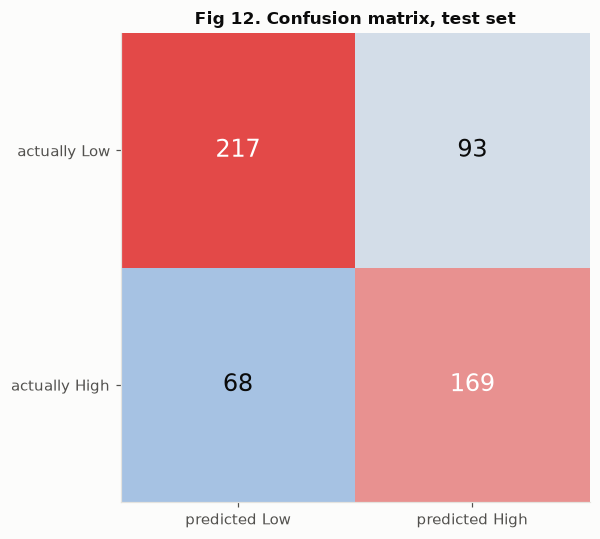

In [327]:
chosen_classifier_name = "Logistic regression"
chosen_classifier = logistic
test_prediction_class = chosen_classifier.predict(X_test)

test_rows = []
for name, prediction in [("Baseline: majority class", np.full(len(y_test), majority_class)),
                         (f"{chosen_classifier_name} (chosen on validation)", test_prediction_class)]:
    test_rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, prediction),
        "precision": precision_score(y_test, prediction, zero_division=0),
        "recall": recall_score(y_test, prediction, zero_division=0),
        "F1": f1_score(y_test, prediction, zero_division=0),
    })
print("Test set, opened once for the model chosen on validation:")
display(pd.DataFrame(test_rows).set_index("model").round(3))

matrix = confusion_matrix(y_test, test_prediction_class)
fig, ax = plt.subplots(figsize=(5.6, 5))
ax.imshow(matrix, cmap=diverging.reversed(), vmin=0, vmax=matrix.max())
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["predicted Low", "predicted High"],
       yticklabels=["actually Low", "actually High"],
       title="Fig 12. Confusion matrix, test set")
ax.grid(False)
for i in range(2):
    for j in range(2):
        ax.text(j, i, matrix[i, j], ha="center", va="center", fontsize=16,
                color="white" if matrix[i, j] > matrix.max() * 0.6 else INK)
fig.tight_layout()
plt.show()

**Fig 12 and the test set.** On authorities it has never seen, logistic regression gets **70.6% right**, with
precision 0.645 and recall 0.713. The confusion matrix: 217 Low rows correctly called Low, 169 High rows
correctly called High, against 93 Low rows called High and 68 High rows called Low.

The two error types are close in size, so the model is not biased towards one class. Recall above precision
means it leans slightly towards calling a row High, which follows from training on a set that was 49% High and
testing on one that is 43%.

70.6% against a near-50% reference lands exactly in the 70 to 80% range we said to expect from a model with
R² 0.530. Nothing is leaking, and nothing surprising has appeared.

In [328]:
# Does the classifier know anything the regression did not?
regression_prediction = chosen_model.predict(X_test)
regression_as_label = (regression_prediction
                       > test_set.join(group_median.rename("cut"), on=GROUP_KEYS)["cut"]).astype(int)

print("Turning the regression's predicted score into the same High/Low label:")
display(pd.DataFrame([
    {"source": "Logistic regression (classifier)",
     "accuracy": accuracy_score(y_test, test_prediction_class),
     "F1": f1_score(y_test, test_prediction_class, zero_division=0)},
    {"source": "Random forest regression, thresholded",
     "accuracy": accuracy_score(y_test, regression_as_label),
     "F1": f1_score(y_test, regression_as_label, zero_division=0)},
]).set_index("source").round(3))
print(f"The two agree on {100 * (test_prediction_class == regression_as_label.to_numpy()).mean():.1f}% "
      "of test rows.")

Turning the regression's predicted score into the same High/Low label:


,accuracy,F1
source,,
Logistic regression (classifier),0.706,0.677
"Random forest regression, thresholded",0.709,0.654


The two agree on 78.1% of test rows.


**The classification track adds nothing the regression had not already given us, and that is worth saying
plainly.** Taking the forest regression from Step 7, comparing its predicted score against the same group
medians, and reading off High or Low gives **70.9% accuracy** — statistically indistinguishable from the
classifier's 70.6%, and on F1 the classifier is marginally ahead (0.677 against 0.654). The two approaches
agree on 78% of test rows.

So the second angle confirms the first rather than extending it. Both say the same thing: roughly 70% of the
time you can tell from an authority's socio-economic profile and the test in question whether it will land
above or below its peers, and roughly 30% of the time you cannot. That residual 30% is the same material Step 8
turned into the over- and under-performer list.

We report this rather than presenting the classifier as an independent success. It cost little, it corroborates
the regression, and claiming more for it would misrepresent what two models built on the same 20 features can
tell us. The one thing it does add is a concrete, readable statement of the limit: **about three authorities in
ten are on the wrong side of where their circumstances would put them.**

## Which variables actually matter

The proposal asked whether the socio-economic index outweighs grade level and subject. We can answer that now,
but only with care, because two things about this feature set make a naive importance ranking misleading.

**The categoricals arrive split.** `subject_id`, `shichva`, `norm_id` and `year` enter the pipeline as separate
dummy columns, 13 of them in total against 16 numeric features. Importance reported per column would make each
categorical look weak purely because it was encoded, so we add the columns back up per original variable before
ranking anything.

**The socio-economic variables are near-duplicates of each other.** Fig 5 showed `ses_index` correlating above
0.8 with eight of the CBS variables. Permutation importance works by shuffling one variable and measuring the
damage, so when eight variables carry the same information, shuffling any one of them does almost nothing and
each looks individually irrelevant. That is an artefact of the correlation, not evidence that socio-economic
standing is unimportant.

So we report three per-variable views, and then the comparison that collinearity cannot distort: shuffling the
**whole socio-economic block together** against the **whole test-identity block together**.

Before running it, what we expect: Step 7's subject × grade baseline alone reached R² 0.297 of the full model's
0.537, so more than half the explained variance is already *which test this is*. Test identity will probably
outweigh socio-economic standing.

In [329]:
from sklearn.inspection import permutation_importance

# Step 11 reassigned y_val to the High/Low label, so the regression target is re-derived explicitly here
score_val = val_set[TARGET]
X_val_features = val_set[FEATURES]

encoded_columns = chosen_model[:-1].get_feature_names_out()

def original_variable(column):
    bare = column.split("__", 1)[1]
    if bare in NUMERIC_FEATURES:
        return bare
    for variable in CATEGORICAL_FEATURES:
        if bare.startswith(variable + "_"):
            return variable
    return bare

owner = pd.Series([original_variable(c) for c in encoded_columns], index=encoded_columns)
print(f"{len(encoded_columns)} encoded columns from {len(FEATURES)} variables. "
      "Columns per categorical variable:")
print(owner.value_counts().loc[CATEGORICAL_FEATURES].to_string())

# 1. the forest's built-in (impurity) importance
impurity = (pd.Series(chosen_model.named_steps["model"].feature_importances_, index=encoded_columns)
            .groupby(owner).sum())

# 2. permutation importance, on validation, measured as lost R2
permutation = permutation_importance(chosen_model, X_val_features, score_val,
                                     n_repeats=15, random_state=RANDOM_STATE, scoring="r2")
permutation = pd.Series(permutation.importances_mean, index=FEATURES)

# 3. the logistic classifier's standardized coefficients, absolute, summed per variable
logistic_columns = logistic[:-1].get_feature_names_out()
logistic_owner = pd.Series([original_variable(c) for c in logistic_columns], index=logistic_columns)
coefficients = (pd.Series(np.abs(logistic.named_steps["model"].coef_[0]), index=logistic_columns)
                .groupby(logistic_owner).sum())

importance = pd.DataFrame({
    "impurity (forest)": impurity,
    "permutation (forest)": permutation,
    "|coefficient| (logistic)": coefficients,
}).fillna(0).sort_values("permutation (forest)", ascending=False)
display(importance.round(4))

29 encoded columns from 20 variables. Columns per categorical variable:
shichva       2
subject_id    5
norm_id       3
year          3


,impurity (forest),permutation (forest),|coefficient| (logistic)
subject_id,0.2719,0.5038,1.9044
shichva,0.1071,0.1694,0.0076
income_per_capita,0.0436,0.0209,0.5594
pct_income_support_20plus,0.0321,0.0183,0.3184
year,0.0326,0.0173,1.1285
population,0.0275,0.0124,0.3216
avg_days_abroad,0.0382,0.0124,0.1739
norm_id,0.0102,0.0122,3.9443
ses_index,0.0450,0.0112,0.0302
avg_years_schooling_25_54,0.0444,0.0112,0.7799


**Subject and grade dominate, and it is not close.** By permutation importance, shuffling `subject_id` costs
**0.504 of R²** and `shichva` **0.169**. The next variable down is `income_per_capita` at 0.021, an order of
magnitude lower. `ses_index` itself ranks **ninth, at 0.011**.

The three views mostly agree on the top two and disagree below that, which is what the method differences
predict.

- **Impurity** spreads weight across the correlated CBS variables, giving `vehicles_per_100_17plus` 0.075 and
  `pct_academic_degree_27_54` 0.052 — more than `ses_index` itself at 0.045. A tree splitting on any one of
  eight near-identical variables records the credit wherever it happened to split.
- **Permutation** does the opposite: it gives each correlated variable almost nothing, because its information
  survives in the other seven.
- **The logistic coefficients** rank `norm_id` first (3.94) while permutation puts it eighth. Sector is a strong
  linear signal but the forest can reconstruct it from the socio-economic variables, so removing it costs little.

One oddity worth reporting rather than hiding: `pct_academic_degree_27_54` has permutation importance of
**−0.012**, meaning validation predictions get slightly *better* when it is shuffled. On this split it is
contributing noise.

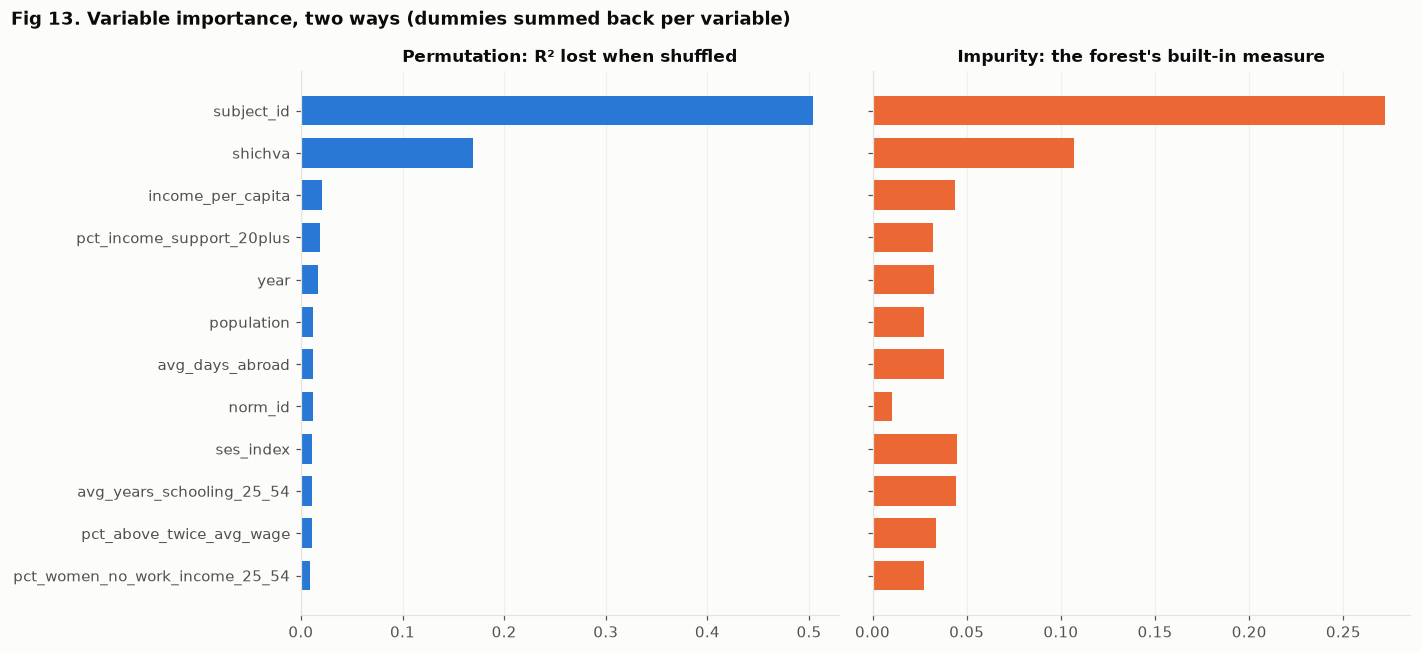

In [330]:
TOP = 12
top_variables = importance.head(TOP).index[::-1]
positions = np.arange(len(top_variables))

fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
for ax, (column, colour, title) in zip(axes, [
        ("permutation (forest)", BLUE, "Permutation: R² lost when shuffled"),
        ("impurity (forest)", ORANGE, "Impurity: the forest's built-in measure")]):
    values = importance.loc[top_variables, column]
    ax.barh(positions, values, color=colour, height=0.7)
    ax.axvline(0, color=INK_MUTED, linewidth=1)
    ax.set(yticks=positions, yticklabels=top_variables, title=title)
    ax.grid(axis="y", visible=False)

fig.suptitle("Fig 13. Variable importance, two ways (dummies summed back per variable)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

**Fig 13.** The left panel is the honest ranking of individually irreplaceable variables; the right panel shows
how impurity importance distributes credit among substitutes. Read together they say: the test a row comes from
is irreplaceable, and no single socio-economic variable is, because they all stand in for each other.

Neither panel answers the proposal's question on its own, which is what the next cell is for.

In [331]:
SOCIO_BLOCK = NUMERIC_FEATURES            # ses_index, population and the 14 CBS variables
TEST_BLOCK = CATEGORICAL_FEATURES         # subject_id, shichva, norm_id, year

baseline_r2 = r2_score(score_val, chosen_model.predict(X_val_features))
generator = np.random.default_rng(RANDOM_STATE)

def block_importance(columns, repeats=20):
    # Shuffle a whole block of columns together, keeping rows aligned within the block, so that
    # correlated variables lose their information at the same time
    drops = []
    for _ in range(repeats):
        shuffled = X_val_features.copy()
        shuffled[columns] = shuffled[columns].to_numpy()[generator.permutation(len(shuffled))]
        drops.append(baseline_r2 - r2_score(score_val, chosen_model.predict(shuffled)))
    return {"R2 lost": np.mean(drops), "sd over repeats": np.std(drops), "variables": len(columns)}

blocks = pd.DataFrame({
    f"socio-economic block": block_importance(SOCIO_BLOCK),
    f"test identity block": block_importance(TEST_BLOCK),
    "subject and grade only": block_importance(["subject_id", "shichva"]),
    "ses_index alone": block_importance(["ses_index"]),
}).T[["variables", "R2 lost", "sd over repeats"]]

print(f"Table 10. Block permutation on validation. Baseline R2 = {baseline_r2:.3f}.")
print("A loss larger than the baseline means the model ends up worse than predicting the mean.")
display(blocks.round(3))

Table 10. Block permutation on validation. Baseline R2 = 0.463.
A loss larger than the baseline means the model ends up worse than predicting the mean.


,variables,R2 lost,sd over repeats
socio-economic block,16.0,0.374,0.034
test identity block,4.0,0.609,0.059
subject and grade only,2.0,0.602,0.051
ses_index alone,1.0,0.012,0.005


**Table 10. The answer to the proposal's question is no.** Shuffling the four test-identity variables costs
**0.609 of R²**; shuffling all sixteen socio-economic variables costs **0.374**. Subject and grade alone cost
0.602, essentially the whole test-identity block. So *which test a row is* carries more of this model's
predictive power than everything we know about the authority's socio-economic circumstances combined.

The losses exceed the 0.463 baseline because a model fed shuffled test identity predicts worse than simply
guessing the mean score: R² goes negative. That is the expected consequence of destroying the variable that
sets the level of each test.

**The contrast between the two importance measures is the methodological point of this step.** Per-variable
permutation says `ses_index` is worth 0.011, close to nothing. The block permutation says socio-economic
information is worth 0.374, which is most of what the model can do beyond knowing the test. Both numbers are
correct, and reporting only the first would have been badly misleading. `ses_index` alone costs 0.010 when
shuffled precisely because the other fifteen variables reconstruct it.

So the honest answer to the question the proposal set: **socio-economic standing does not outweigh grade and
subject, but it is not negligible either.** It is the second of two large blocks, and its contribution is
spread so thinly across correlated variables that no single one of them looks important. For Correction 6 this
also closes the loop: the wider predictor set the instructor asked for did make the feature-importance analysis
meaningful, but mainly by revealing that the index has fifteen substitutes rather than by promoting any one of
them.

## Does any of this depend on the choices we made?

Six judgement calls shaped everything above: which years to keep, whether to use combined totals or sector
rows, whether to drop small cells, which socio-economic measure to use, how to split, and which model family.
Each was defensible, and each could have gone the other way. This section rebuilds the whole pipeline under
each alternative and checks what survives.

**The metric is the authority list, not R².** A variation could leave R² untouched while reshuffling which
authorities get flagged, or move R² while leaving the list intact. Since the 64 over- and under-performers are
the project's output, what matters is how many of them survive and whether any of them changes direction.

Three of the six were already answered earlier and are collected here rather than re-run: the row-level split
(Step 6: 236 of 243 authorities land in two sets, and authority averages alone give R² 0.30), the weighting
(Step 7: forest R² 0.463 to 0.413), and the forest-versus-linear comparison of the gaps (Step 8: Spearman
0.849). The rest are rebuilt from the raw files below.

⚠️ **One limitation.** Each variant reuses the hyperparameters tuned on the baseline rather than re-tuning. That
keeps the comparison about the data choice instead of mixing in a second search, and it keeps this section to a
few minutes of runtime, but a variant that would have preferred different settings is mildly disadvantaged.

In [332]:
from sklearn.linear_model import LinearRegression as _LinearRegression

raw_education = pd.read_csv(EDUCATION_PATH)          # before the year filter and the norm_id fix
BEST_FOREST = {k.removeprefix("model__"): v for k, v in rf_search["unweighted"].best_params_.items()}
print("Reusing the baseline forest settings:", BEST_FOREST)

def rebuild(years=(2016, 2017, 2018), grain="totals", min_tested=0, ses="ses_index"):
    rows = raw_education[raw_education["year"].isin(years)].reset_index(drop=True)
    if grain == "totals":
        has_total = rows["norm_id"].eq(1).groupby([rows[k] for k in KEYS]).transform("any")
        rows = rows[~has_total | rows["norm_id"].eq(1)]
    else:
        rows = rows[rows["norm_id"] != 1]
    rows = rows.reset_index(drop=True)
    rows["cbs_key"] = rows["rashut"].map(cbs_key_from_rashut)
    merged = rows.merge(cbs, on="cbs_key", how="left")
    merged = merged[merged["ses_index"].notna() & merged["score"].notna()]
    if min_tested:
        merged = merged[merged["n_students_tested"] >= min_tested]
    merged = merged.drop(columns=[c for c in merged.columns if c.endswith(("_z", "_rank"))])
    return (merged.reset_index(drop=True),
            [ses, "population"] + CBS_VARIABLES,
            ["shichva", "subject_id", "norm_id", "year"])

def variant_pipeline(numeric, categorical, model):
    numeric_steps = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    prep = ColumnTransformer([("num", numeric_steps, numeric),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), categorical)])
    return Pipeline([("prep", prep), ("model", model)])

def flag_under(frame, numeric, categorical, model=None):
    # The whole Step 8 chain: out-of-fold prediction, standardize within test, flag the consistent ones
    model = model or RandomForestRegressor(n_estimators=400, random_state=RANDOM_STATE,
                                           n_jobs=-1, **BEST_FOREST)
    X, y = frame[numeric + categorical], frame["score"]
    out_of_fold = cross_val_predict(variant_pipeline(numeric, categorical, model), X, y,
                                    cv=GroupKFold(n_splits=5), groups=frame["rashut"])
    residual = pd.Series(y.to_numpy() - out_of_fold, index=frame.index)
    by_test = residual.groupby([frame["subject_id"], frame["shichva"]])
    variant_gap = (residual - by_test.transform("mean")) / by_test.transform("std")
    by_authority = variant_gap.groupby(frame["rashut"])
    per = pd.DataFrame({"rows": by_authority.size(), "gap": by_authority.mean(), "sd": by_authority.std(),
                        "same_sign": by_authority.apply(
                            lambda s: float((np.sign(s) == np.sign(s.mean())).mean()))})
    per["t"] = per["gap"] / (per["sd"] / np.sqrt(per["rows"]))
    candidates = per[per["rows"] >= 2]
    picked = candidates[(candidates["t"].abs() >= 2) & (candidates["same_sign"] >= 1.0)]
    return {"rows": len(frame), "authorities": frame["rashut"].nunique(),
            "r2": r2_score(y, out_of_fold), "flagged": set(picked.index),
            "over": set(picked.index[picked["gap"] > 0]), "under": set(picked.index[picked["gap"] < 0])}

# The baseline must reproduce what the notebook already reported, or the rebuild is wrong
baseline_frame, baseline_numeric, baseline_categorical = rebuild()
runs = {"baseline (as reported above)": flag_under(baseline_frame, baseline_numeric, baseline_categorical)}
check = runs["baseline (as reported above)"]
print(f"Rebuilt baseline: {check['rows']} rows, {check['authorities']} authorities, "
      f"out-of-fold R2 {check['r2']:.3f}, {len(check['flagged'])} flagged "
      f"({len(check['over'])} over / {len(check['under'])} under)")
assert (check["rows"], check["authorities"], len(check["flagged"])) == (1749, 243, 64), \
    "the rebuild does not reproduce the baseline, so the variants below cannot be trusted"
print("Matches the figures reported earlier, so the variants are comparable.")

Reusing the baseline forest settings: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1}
Rebuilt baseline: 1749 rows, 243 authorities, out-of-fold R2 0.537, 64 flagged (33 over / 31 under)
Matches the figures reported earlier, so the variants are comparable.


In [333]:
VARIATIONS = [
    ("Sector rows instead of combined totals", dict(grain="sectors")),
    ("All years 2015-2019 instead of 2016-2018", dict(years=(2015, 2016, 2017, 2018, 2019))),
    ("Drop cells under 30 students tested", dict(min_tested=30)),
    ("Drop cells under 50 students tested", dict(min_tested=50)),
    ("ses_cluster instead of ses_index", dict(ses="ses_cluster")),
]
for label, settings in VARIATIONS:
    frame, numeric, categorical = rebuild(**settings)
    runs[label] = flag_under(frame, numeric, categorical)

runs["Linear regression instead of the forest"] = flag_under(
    baseline_frame, baseline_numeric, baseline_categorical, model=_LinearRegression())

baseline_flagged = runs["baseline (as reported above)"]["flagged"]
baseline_over = runs["baseline (as reported above)"]["over"]

sensitivity = pd.DataFrame([{
    "variation": label,
    "rows": run["rows"],
    "out-of-fold R2": run["r2"],
    "authorities flagged": len(run["flagged"]),
    "of the baseline 64, kept": len(run["flagged"] & baseline_flagged),
    "changed direction": sum(1 for a in run["flagged"] & baseline_flagged
                             if (a in run["over"]) != (a in baseline_over)),
} for label, run in runs.items()]).set_index("variation")

print("Table 11. Every row is a full rebuild of the pipeline, from the raw files to the flagged list.")
display(sensitivity.round(3))

Table 11. Every row is a full rebuild of the pipeline, from the raw files to the flagged list.


,rows,out-of-fold R2,authorities flagged,"of the baseline 64, kept",changed direction
variation,,,,,
baseline (as reported above),1749,0.537,64,64,0
Sector rows instead of combined totals,1826,0.510,59,55,0
All years 2015-2019 instead of 2016-2018,2540,0.570,44,37,0
Drop cells under 30 students tested,1747,0.536,64,56,0
Drop cells under 50 students tested,1653,0.560,68,55,0
ses_cluster instead of ses_index,1749,0.541,62,60,0
Linear regression instead of the forest,1749,0.400,50,34,0


**Table 11. No authority ever changes direction.** The last column is zero on every row. Across six rebuilds,
including one that changes the model family and one that adds two years of data, **not a single authority ever
flips from over-performing to under-performing**. That is the result that matters most, and it is the strongest
claim this project can make.

Everything else is more qualified.

- **The measure barely matters.** Swapping the continuous index for the 1 to 10 cluster keeps 60 of the 64 and
  moves R² from 0.537 to 0.541. Step 12 predicted this: `ses_index` has fifteen near-substitutes, so coarsening
  it changes very little.
- **The data-shape choices cost a handful each.** Sector rows keep 55 of 64, the cutoff at 50 keeps 55, the
  cutoff at 30 keeps 56.
- ⚠️ **The cutoff at 30 removes only 2 rows, yet 8 of the 64 drop off the list.** That is the single most
  informative line in the table. The flagging rule is a hard threshold, so authorities sitting just at the
  boundary move in and out on almost nothing. The membership of the list is a snapshot, not a fixed roster.
- **The year window matters most.** Using all of 2015-2019 keeps only 37 of 64, though R² rises to 0.570. This
  is mechanical rather than contradictory: more years means more rows per authority, and the rule requires
  *every* row to agree in sign, which gets harder the more rows there are. It is the rule tightening, not the
  finding weakening.
- **The model family matters next.** Linear regression keeps 34 of 64 at R² 0.400, consistent with the Spearman
  0.849 from Step 8: the ranking is similar, but a weaker model pushes fewer authorities past the bar.

In [334]:
# Which authorities survive every single rebuild?
core = set.intersection(*(run["flagged"] for run in runs.values()))
core_over = set.intersection(*(run["over"] for run in runs.values()))

core_table = (per_authority.loc[sorted(core), ["name_en", "rows", "gap", "t", "ses_cluster"]]
              .assign(group=lambda f: ["over-performer" if a in core_over else "under-performer"
                                       for a in f.index])
              .sort_values("gap", ascending=False))
print(f"Flagged in all {len(runs)} rebuilds: {len(core)} authorities "
      f"({len(core_over)} over, {len(core) - len(core_over)} under)")
display(core_table.round(2))
core_table.to_excel(Path("data") / "robust_authorities.xlsx")

Flagged in all 7 rebuilds: 21 authorities (13 over, 8 under)


,name_en,rows,gap,t,ses_cluster,group
rashut,,,,,,
5074,KAFAR YASIF,5,2.12,5.19,4,over-performer
7800000,HAR HEVRON,7,1.43,4.22,5,over-performer
6817,GIV'AT SHEMU'EL,7,1.40,6.90,8,over-performer
37697,HAR ADAR,3,1.27,11.51,9,over-performer
5025,YIRKA,7,1.25,4.75,3,over-performer
12963,KISRA-SUMEI,7,1.00,7.30,3,over-performer
5314,ARRABE,7,0.99,5.00,3,over-performer
4663,BET DAGAN,3,0.96,9.43,7,over-performer
2402,YOQNE'AM ILLIT,5,0.91,8.59,7,over-performer


**The robust core: 21 authorities.** These are flagged under every one of the seven rebuilds — both grains,
three small-cell rules, both socio-economic measures, both year windows and both model families. Thirteen
over-perform and eight under-perform.

**Over-performing:** Kafar Yasif, Har Hevron, Giv'at Shemu'el, Har Adar, Yirka, Kisra-Sumei, Arrabe, Bet Dagan,
Yoqne'am Illit, Tel Mond, Efrat, Binyamina-Giv'at Ada, Qiryat Yam.

**Under-performing:** Laqye, Jisr az-Zarqa, Basmat Tab'un, Hagalil Haelyon, Lehavim, Emeq Hama'ayanot, Be'er
Sheva, Pardes Hanna-Karkur.

This is the list to put in the report, rather than the 64. It is smaller and it is honest: these authorities
depart from their socio-economic prediction no matter which defensible version of the analysis is run. Both
lists mix sectors, clusters and authority types, which is the same point Fig 8 made and Table 7 could not
explain.

The 64 is still the right headline count for "how many authorities deviate consistently", because it comes from
the single pre-specified analysis. The 21 answers a different and stricter question: which of them would
survive a reviewer rebuilding the project with different reasonable choices. Reporting both, and the
distinction between them, is more defensible than reporting either alone.